# Classification of Genetic Disorders Using Quantum Machine Learning: A Comparative Study with Classical Models
### Comparison between a quantum neural network (QNN) and a multilayer perceptron (MLP) using Qiskit Machine Learning to classify genetic disorders based on clinical data.

**Hackathon:** Qollab Quantum Hackathon

**Equipo:** Axolotl team

**Integrantes:** Luis Arturo Tapia Alarcón - Leader

**Fecha:** 9-11 november 2016

## Project Summary

A hybrid quantum machine learning pipeline was developed to address the classification of genetic disorders (mitochondrial vs. single-gene) based on clinical and hereditary data—a challenging problem due to reported weak predictive signals, missing values, and class imbalance. We utilized the "Of Genomes and Genetics" dataset (HackerEarth, Kaggle), comprising 22,083 patient records, employing a workflow that included exploratory analysis, imputation, and the selection of the 10 variables with the highest mutual information (symptoms, blood cell counts, and maternal/paternal inheritance indicators), followed by dimensionality reduction via PCA to align with the required number of qubits.

The solution incorporates a quantum neural network (QNN) from Qiskit Machine Learning—executed on a simulator and trained using PyTorch—to classify patients via a variational circuit featuring a data-encoding feature map. We evaluated the model using 5-fold stratified cross-validation across multiple seeds, measuring macro F1 score and accuracy on a consistent balanced subsample, and compared the results against a multilayer perceptron (MLP) with an equivalent number of trainable parameters. We obtained [Macro F1 ± deviation for the QNN and MLP, with N qubits, P parameters, and M samples], which [demonstrates comparable performance / shows differences within statistical noise] and evidences the approach's viability given the current limitations of NISQ hardware.

## 1. Problem and objective

### Problem
Early diagnosis of genetic disorders is challenging because it depends on
multiple simultaneous variables—hereditary history, symptoms, laboratory
results, and pregnancy history—often involving incomplete clinical data.
Clinical genetics specialists and diagnostic support teams face this
difficulty, and classical models applied to this type of data achieve
limited performance (in this dataset, barely above the majority-class
baseline). This motivates exploring whether quantum machine learning
can offer a viable alternative for classifying the disorder type.

### Objective
To develop and evaluate a hybrid quantum neural network (QNN)—implemented
using Qiskit Machine Learning—capable of classifying genetic disorders
(mitochondrial vs. single-gene) and to compare it with a multilayer
perceptron (MLP) of equivalent size, using the "Of Genomes and Genetics"
dataset (22,083 clinical records), a selection of 10 variables, and a
quantum simulator with a reduced number of qubits.

### Success criterion
The proposal will be considered successful if [the QNN and MLP are trained
and evaluated under identical conditions (same subsample, variables,
seeds, and 5-fold cross-validation), both outperform—in terms of macro-F1
score—a classifier that always predicts the majority class (57.1% accuracy
in the binary task), and the difference between the QNN and MLP is reported
as mean ± standard deviation, indicating whether it is statistically
distinguishable].

### Scope
In this prototype, we address the binary classification between
mitochondrial and single-gene disorders using a QNN on a simulator,
compared against an MLP. Excluded are the multifactorial class and the 9 subclasses, execution on real quantum hardware, QPCA, exhaustive hyperparameter tuning, and any clinical validation or use of the results.

## 2. Proposed Solution

The solution takes a patient's clinical record (symptoms, blood cell count, and maternal and paternal inheritance indicators), performs preprocessing (imputation, scaling, and reduction to a small number of features—one per qubit), processes it using a hybrid quantum neural network (QNN), and returns the predicted class (mitochondrial or single-gene disorder) along with its probability.

The workflow is as follows:

1. Load and verify data: read `train.csv`, discard identifiers, names, constant columns, and unlabeled rows, and check for null values ​​and class distribution.
2. Prepare model inputs: impute missing values, select the 10 variables with the highest mutual information, scale them, and—if justified by the explained variance—apply PCA to adjust the number of qubits. A stratified, balanced subsample is created.
3. Train a classical benchmark: a multilayer perceptron (MLP) with a number of trainable parameters equivalent to that of the QNN, alongside a baseline that always predicts the majority class.
4. Build and train the QML model: a Qiskit Machine Learning QNN (`EstimatorQNN` or `SamplerQNN`) with a feature map and variational ansatz, executed on a simulator and trained with PyTorch via `TorchConnector`.
5. Compare results under the same protocol: same subsample, same variables, same seeds, and 5-fold stratified cross-validation, reporting macro F1 score and accuracy as mean ± standard deviation.
6. Run a solution demonstration: input an example patient record and display the prediction and probability from the QNN versus the MLP. ### Function of the quantum component
The quantum circuit serves as a classifier: a feature map encodes
patient characteristics into qubit states, a variational ansatz
with trainable parameters transforms that state, and the circuit
measurement yields the probability for each class.

We chose this approach to evaluate whether, using very few qubits and
parameters, the QNN achieves performance comparable to an MLP of
equivalent size on tabular clinical data with weak signals, and to
identify the limitations that arise (simulation cost, sensitivity to the
choice of feature map, and variability across seeds). We do not assume
a quantum advantage a priori; rather, we are evaluating the
feasibility of the approach.

## 3. How to run this notebook

### Requirements
- Python: 3.14.5

- Main libraries: `qiskit`, `qiskit-machine-learning`, `qiskit-aer`, `torch`, `scikit-learn`,
`pandas`, `numpy`, and `matplotlib`.

- Resources: CPU only with a local quantum simulator (`qiskit-aer` or
Qiskit reference primitives). No GPU or QPU access required. [Hardware
used: CPU, cores, and RAM.]

- Data: "Of Genomes and Genetics" dataset (HackerEarth, Kaggle). Only
`train.csv` is used, as `test.csv` does not include labels. Download
manually from the Kaggle dataset page or via the Kaggle API.

### Instructions
1. Prepare the environment and install dependencies
(`pip install -r requirements.txt`).

2. Download the dataset and place `train.csv` in `data/train.csv`.

3. Configure the parameters in the first cell: seed (`SEED`), number
of qubits (`N_QUBITS`), subsample size (`N_SAMPLES`), number of
cross-validation folds, and number of training iterations.

4. Restart the kernel and run the cells in order.

In [1]:
# =============================================================================
# DEEP LEARNING FRAMEWORK
# =============================================================================
# PyTorch standard CPU build (skipping CUDA index-url for pure CPU use).
%pip install torch
#
# torchvision / torchaudio are not needed for this tabular dataset.


# =============================================================================
# QUANTUM MACHINE LEARNING FRAMEWORK
# =============================================================================
# Qiskit + QNN tools. qiskit-machine-learning >= 0.8 is required because
# EstimatorQNN is fed with V2 primitives (qiskit_aer.primitives.EstimatorV2).
%pip install qiskit "qiskit-machine-learning>=0.8"

# Quantum simulation on CPU (standard qiskit-aer package).
%pip install qiskit-aer

# Optional: access to IBM quantum hardware (only needed if ENABLE_IBM = True).
# %pip install qiskit-ibm-runtime


# =============================================================================
# DATA SCIENCE AND NUMERICAL COMPUTING
# =============================================================================
# Tables, numerical computing and statistics.
%pip install pandas numpy scipy

# Preprocessing, feature selection and baseline models.
%pip install scikit-learn

# Model persistence and progress bars.
%pip install joblib tqdm

# ipywidgets: required by `tqdm.auto` to render progress bars in Jupyter.
# ipython is imported directly (IPython.display); both are normally present
# with Jupyter, installing them is harmless and makes the cell self-contained.
%pip install ipython ipywidgets

# Hardware inspection utilities.
%pip install py-cpuinfo psutil


# =============================================================================
# VISUALIZATION LIBRARIES
# =============================================================================
%pip install matplotlib seaborn


# =============================================================================
# KAGGLE DATASET DOWNLOAD AND MANAGEMENT
# =============================================================================
%pip install kagglehub

# Restart the kernel now, then run the verification cell below.


# %% Verification cell (run AFTER restarting the kernel)
# Confirms every package imports, lists installed versions and checks that
# CPU paths (PyTorch and Aer) are visible before running Step 2.
import importlib
from importlib.metadata import PackageNotFoundError, version
import torch
from qiskit_aer import AerSimulator

CHECKS = {
    # distribution name (candidates)             : import name
    ("numpy",): "numpy",
    ("pandas",): "pandas",
    ("scipy",): "scipy",
    ("scikit-learn",): "sklearn",
    ("matplotlib",): "matplotlib",
    ("seaborn",): "seaborn",
    ("joblib",): "joblib",
    ("tqdm",): "tqdm",
    ("ipywidgets",): "ipywidgets",
    ("py-cpuinfo",): "cpuinfo",
    ("psutil",): "psutil",
    ("kagglehub",): "kagglehub",
    ("torch",): "torch",
    ("qiskit",): "qiskit",
    ("qiskit-machine-learning",): "qiskit_machine_learning",
    ("qiskit-aer",): "qiskit_aer",
}

failed = []
for dists, module in CHECKS.items():
    ver = "Not installed"
    for dist in dists:
        try:
            ver = version(dist)
            break
        except PackageNotFoundError:
            pass
    try:
        importlib.import_module(module)
        status = "OK"
    except Exception as exc:  # noqa: BLE001 - report every import problem
        status = f"IMPORT ERROR: {exc}"
        failed.append(module)
    print(f"{dists[0]:<28} {ver:<14} {status}")

# Hardware visibility ---------------------------------------------------------
print("\nPyTorch CUDA available:", torch.cuda.is_available())
print("Aer devices:", AerSimulator().available_devices())

assert not failed, f"Fix these imports before continuing: {failed}"
print("\nEnvironment ready for Step 2 (CPU mode).")

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   ----- ---------------------------------- 1.3/9.7 MB 5.0 MB/s eta 0:00:02
   --------- ------------------------------ 2.4/9.7 MB 5.0 MB/s eta 0:00:02
   ------------ --------------------------- 3.1/9.7 MB 5.0 MB/s eta 0:00:02
   -------------- ------------------------- 3.4/9.7 MB 3.8 MB/s eta 0:00:02
   ---------------- ----------------------- 3.9/9.7 MB 3.6 MB/s eta 0:00:02
   ------------------ --------------------- 4.5/9.7 MB 3.5 MB/s eta 0:00:02
   --------------------- ------------------ 5.2/9.7 MB 3.5 MB/s eta 0:00:02
   ------------------------ --------------- 6.0/9.7 MB 3.6 MB/s eta 0:00:02
   ---------------------------- ----------- 6.8/9.7 MB 3.5 MB/s eta 0:00:01
   ------------------------------- -------- 7.6/9.7 MB 3.5 MB/s eta 0:00:01
   ------------------------------------ --- 8.9/9.7 MB 3.8 MB/s eta 0:00:01
   -----------------------

...

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


numpy                        2.5.3          OK
pandas                       3.0.6          OK
scipy                        1.18.1         OK
scikit-learn                 1.9.1          OK
matplotlib                   3.11.2         OK
seaborn                      0.13.2         OK
joblib                       1.6.0          OK
tqdm                         4.70.1         OK
ipywidgets                   8.1.9          OK
py-cpuinfo                   9.0.0          OK
psutil                       7.2.2          OK
kagglehub                    1.0.2          OK
torch                        2.14.1         OK
qiskit                       2.5.2          OK
qiskit-machine-learning      0.9.1          OK
qiskit-aer                   0.17.2         OK

PyTorch CUDA available: False
Aer devices: ('CPU',)

Environment ready for Step 2 (CPU mode).


In [2]:
# =============================================================================
# STEP 2: CORE LIBRARIES, HARDWARE AUDIT AND CPU CONFIGURATION
# =============================================================================
"""
Environment bootstrap for a hybrid classical-quantum neural network (QNN)
pipeline on genomic tabular data (target: "Disorder Subclass").

Stack and responsibilities
--------------------------
    pandas / SciPy / scikit-learn      EDA, preprocessing, classical baselines (CPU)
    PyTorch (CPU)                      classical layers of the hybrid model (CPU)
    Qiskit + Qiskit Aer (CPU)          ideal (noiseless) statevector simulation
    Qiskit Machine Learning            EstimatorQNN / SamplerQNN
    TorchConnector                     exposes a QNN as a torch.nn.Module

What this cell does (in order)
------------------------------
    1. Imports every library used by later steps, grouped by purpose.
    2. Seeds all RNGs and configures deterministic behaviour.
    3. Audits hardware specifications (CPU and RAM).
    4. Builds the Aer backend + Estimator/Sampler primitives for CPU execution.
    5. Creates output folders, records dependency versions and writes a
       JSON environment report for reproducibility.

Design decisions
----------------
    * Pure CPU execution to avoid platform and driver compatibility issues.
    * Nothing here connects to IBM Quantum or submits remote jobs.
    * Names consumed by later cells are kept stable (see "Public API" below).

Public API exported to later cells
----------------------------------
    Seeds / RNG    : GLOBAL_SEED, SEED, rng, seed_worker, make_loader_generator
    Torch          : device, classical_device, TORCH_DTYPE, N_JOBS,
                     DATALOADER_WORKERS, PIN_MEMORY
    Quantum        : AER_BACKEND_OPTIONS, aer_simulator, estimator, sampler,
                     ESTIMATOR_PRECISION, SAMPLER_SHOTS, N_QUBITS
    Paths / config : PROJECT_DIR, OUTPUT_DIR, FIGURES_DIR, TABLES_DIR,
                     MODELS_DIR, LOGS_DIR, DATASET_ID, TARGET, TARGET_COLUMNS,
                     VALID_SIZE, RUN_TIMESTAMP
"""

# =============================================================================
# STANDARD LIBRARIES
# =============================================================================
import os
import copy
import json
import platform
import random
import sys
import time
import warnings

from datetime import datetime
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path

import cpuinfo            # py-cpuinfo: human-readable CPU brand string
import joblib
import kagglehub
import psutil

from IPython.display import display
from tqdm.auto import tqdm


# =============================================================================
# NUMERICAL AND DATA SCIENCE LIBRARIES
# =============================================================================
import numpy as np
import pandas as pd

# Statistical tests / distances, used in EDA and in train-vs-validation drift
# checks (distribution shift, categorical association, rank correlation).
from scipy.stats import (
    chi2_contingency,
    ks_2samp,
    spearmanr,
    wasserstein_distance,
)


# =============================================================================
# VISUALIZATION LIBRARIES
# =============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,       # on-screen resolution
    "savefig.dpi": 300,      # publication-quality exports
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})

pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 60)
pd.set_option("display.precision", 4)


# =============================================================================
# MACHINE LEARNING AND PREPROCESSING (ANTI-OVERFITTING TOOLKIT)
# =============================================================================
# NOTE: several of these imports are not used in this cell; they are collected
# here so that every later step shares one import namespace. Prune once the
# pipeline is final.
from sklearn.base import BaseEstimator, TransformerMixin, clone

# Cross-validation. StratifiedGroupKFold preserves class balance while keeping
# related samples (e.g. same patient/family) in the same fold -> avoids leakage.
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedGroupKFold,
    StratifiedKFold,
    cross_validate,
    learning_curve,
    train_test_split,
)

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    FunctionTransformer,
    LabelEncoder,
    MinMaxScaler,
    OneHotEncoder,
    RobustScaler,
    StandardScaler,
)

from sklearn.feature_selection import (
    SelectKBest,
    VarianceThreshold,
    f_classif,
    mutual_info_classif,
)

from sklearn.decomposition import PCA   # candidate for qubit-budget reduction

# Classical reference models (scikit-learn runs on CPU). They provide the
# baselines the QNN must beat to justify its cost.
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    make_scorer,
    precision_score,
    recall_score,
    roc_auc_score,
)

from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_class_weight


# =============================================================================
# PYTORCH DEEP LEARNING ENVIRONMENT (CPU)
# =============================================================================
import torch
import torch.nn as nn

from torch.optim import Adam, AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import (
    DataLoader,
    Subset,
    TensorDataset,
    WeightedRandomSampler,
)

# float32 for the classical layers. The quantum simulation runs in float64
# ("double" precision); TorchConnector handles the dtype boundary.
TORCH_DTYPE = torch.float32


# =============================================================================
# QUANTUM MACHINE LEARNING BACKENDS (CPU)
# =============================================================================
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Parameter, ParameterVector
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

from qiskit_aer import AerSimulator
from qiskit_aer.primitives import EstimatorV2 as AerEstimatorV2
from qiskit_aer.primitives import SamplerV2 as AerSamplerV2

from qiskit_machine_learning.connectors import TorchConnector
from qiskit_machine_learning.neural_networks import EstimatorQNN, SamplerQNN


# =============================================================================
# IBM QUANTUM (OPTIONAL, DISABLED BY DEFAULT)
# =============================================================================
ENABLE_IBM = False

if ENABLE_IBM:
    try:
        from qiskit_ibm_runtime import (
            EstimatorV2 as RuntimeEstimatorV2,
            QiskitRuntimeService,
            SamplerV2 as RuntimeSamplerV2,
        )
    except ImportError as exc:
        raise ImportError(
            "Instala qiskit-ibm-runtime para habilitar IBM Quantum."
        ) from exc


# =============================================================================
# GLOBAL STOCHASTIC SEEDING AND DETERMINISM
# =============================================================================
GLOBAL_SEED = 42
SEED = GLOBAL_SEED   # backwards-compatible alias used by later cells

STRICT_DETERMINISM = False


def seed_everything(seed: int = GLOBAL_SEED) -> np.random.Generator:
    """Seed every RNG in the stack.

    Covers Python's `random`, NumPy (legacy global state *and* a modern
    `Generator`), and PyTorch (CPU).

    Returns
    -------
    numpy.random.Generator
        A fresh generator for code that prefers the new NumPy RNG API.
    """
    random.seed(seed)
    np.random.seed(seed)            # legacy API, still used by some libraries
    torch.manual_seed(seed)

    return np.random.default_rng(seed)


rng = seed_everything(GLOBAL_SEED)


def seed_worker(worker_id: int) -> None:
    """`worker_init_fn` for DataLoader: seeds NumPy/random in each worker."""
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_loader_generator(seed: int = GLOBAL_SEED) -> torch.Generator:
    """Return a seeded `torch.Generator` for reproducible DataLoader shuffling."""
    generator = torch.Generator()
    generator.manual_seed(seed)
    return generator


# =============================================================================
# HARDWARE AUDIT
# =============================================================================
def get_hardware_specs() -> None:
    """Print CPU, RAM, PyTorch and OS details for the run log."""
    line = "=" * 65
    print(line)
    print("SYSTEM HARDWARE SPECIFICATIONS (CPU MODE)")
    print(line)

    try:
        processor = cpuinfo.get_cpu_info().get("brand_raw", "Unknown Processor")
    except Exception:
        processor = platform.processor() or "Unknown Processor"

    print(f"Processor:          {processor}")
    print(f"Architecture:       {platform.machine()}")
    print(
        "CPU cores:          "
        f"{psutil.cpu_count(logical=False)} physical / "
        f"{psutil.cpu_count(logical=True)} logical"
    )

    ram = psutil.virtual_memory()
    print(f"Total RAM:          {ram.total / 1024**3:.2f} GB")
    print(f"Available RAM:      {ram.available / 1024**3:.2f} GB")

    print(f"PyTorch version:    {torch.__version__}")
    print(f"Operating system:   {platform.system()} {platform.release()}")
    print(f"Python:             {platform.python_version()}")
    print(f"Python executable:  {sys.executable}")
    print(line)


get_hardware_specs()


# =============================================================================
# DEVICE CONFIGURATION: PYTORCH (CPU)
# =============================================================================
device = torch.device("cpu")
classical_device = device    # explicit alias: device for the classical layers

# Multiple jobs can run in parallel using CPU cores safely.
N_JOBS = -1

DATALOADER_WORKERS = 2
PIN_MEMORY = False

print(f"\nPyTorch device: {device}")


# =============================================================================
# DEVICE CONFIGURATION: QISKIT AER (CPU)
# =============================================================================
# Single source of truth for the simulator configuration.
AER_BACKEND_OPTIONS = {
    "method": "statevector",
    "device": "CPU",
    "precision": "double",
    "seed_simulator": GLOBAL_SEED,
}

aer_simulator = AerSimulator(**AER_BACKEND_OPTIONS)

# --- Estimator primitive (for EstimatorQNN) ---------------------------------
ESTIMATOR_PRECISION = 0.0

estimator = AerEstimatorV2(
    options={
        "backend_options": AER_BACKEND_OPTIONS.copy(),
        "default_precision": ESTIMATOR_PRECISION,
    }
)

# --- Sampler primitive (for SamplerQNN) -------------------------------------
SAMPLER_SHOTS = 1024

sampler = AerSamplerV2(
    default_shots=SAMPLER_SHOTS,
    seed=GLOBAL_SEED,
    options={"backend_options": AER_BACKEND_OPTIONS.copy()},
)

# Initial qubit budget; memory grows as 2^N * 16 bytes in double precision.
N_QUBITS = 4


# =============================================================================
# CPU EXECUTION CHECKS
# =============================================================================
def verify_aer_cpu_execution() -> None:
    """Prove that Aer executes successfully on CPU and returns correct results."""
    bell = QuantumCircuit(2)
    bell.h(0)
    bell.cx(0, 1)

    backend_check = bell.copy()
    backend_check.save_statevector()

    result = aer_simulator.run(backend_check).result()
    if not result.success:
        raise RuntimeError(f"La prueba de Aer CPU falló: {result.status}")

    amplitudes = np.asarray(result.get_statevector())
    expected = np.array([1, 0, 0, 1]) / np.sqrt(2)
    assert np.allclose(amplitudes, expected, atol=1e-8), (
        "Bell-state amplitudes differ from the analytical result."
    )

    print("\nAer CPU execution: OK")

    observable = SparsePauliOp.from_list([("ZZ", 1.0)])
    evs = estimator.run([(bell, observable)]).result()[0].data.evs
    assert np.allclose(evs, 1.0, atol=1e-8), f"<ZZ> = {evs}, expected 1.0"

    print("Aer EstimatorV2 execution: OK")


verify_aer_cpu_execution()


# =============================================================================
# GLOBAL FILE AND EXPERIMENT CONFIGURATION
# =============================================================================
PROJECT_DIR = Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "outputs"

FIGURES_DIR = OUTPUT_DIR / "figures"
TABLES_DIR = OUTPUT_DIR / "tables"
MODELS_DIR = OUTPUT_DIR / "models"
LOGS_DIR = OUTPUT_DIR / "logs"

for folder in (FIGURES_DIR, TABLES_DIR, MODELS_DIR, LOGS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DATASET_ID = (
    "aryarishabh/"
    "of-genomes-and-genetics-hackerearth-ml-challenge"
)

TARGET = "Disorder Subclass"
TARGET_COLUMNS = ["Genetic Disorder", "Disorder Subclass"]
VALID_SIZE = 0.20

RUN_TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")


# =============================================================================
# DEPENDENCY VERSION AUDIT
# =============================================================================
def resolve_version(*distribution_names: str) -> str:
    """Return the installed version of the first distribution that exists."""
    for name in distribution_names:
        try:
            return version(name)
        except PackageNotFoundError:
            continue
    return "Not installed"


PACKAGES = {
    "numpy": ("numpy",),
    "pandas": ("pandas",),
    "scipy": ("scipy",),
    "matplotlib": ("matplotlib",),
    "seaborn": ("seaborn",),
    "scikit-learn": ("scikit-learn",),
    "kagglehub": ("kagglehub",),
    "psutil": ("psutil",),
    "py-cpuinfo": ("py-cpuinfo",),
    "joblib": ("joblib",),
    "tqdm": ("tqdm",),
    "torch": ("torch",),
    "qiskit": ("qiskit",),
    "qiskit-machine-learning": ("qiskit-machine-learning",),
    "qiskit-aer": ("qiskit-aer",),
}

if ENABLE_IBM:
    PACKAGES["qiskit-ibm-runtime"] = ("qiskit-ibm-runtime",)

dependency_versions = {
    label: resolve_version(*names) for label, names in PACKAGES.items()
}

display(pd.DataFrame(
    dependency_versions.items(),
    columns=["package", "version"],
))


# =============================================================================
# ENVIRONMENT REPORT (REPRODUCIBILITY)
# =============================================================================
environment_report = {
    "timestamp": RUN_TIMESTAMP,
    "python": platform.python_version(),
    "platform": platform.platform(),
    "seed": GLOBAL_SEED,
    "strict_determinism": STRICT_DETERMINISM,
    "torch_device": str(device),
    "aer_backend_options": AER_BACKEND_OPTIONS,
    "estimator_precision": ESTIMATOR_PRECISION,
    "sampler_shots": SAMPLER_SHOTS,
    "n_qubits": N_QUBITS,
    "packages": dependency_versions,
}

environment_file = LOGS_DIR / f"environment_{RUN_TIMESTAMP}.json"
environment_file.write_text(
    json.dumps(environment_report, indent=2),
    encoding="utf-8",
)

print("\nConfiguración CPU completada.")
print("QNN framework: Qiskit Machine Learning")
print("Hybrid connector: TorchConnector")
print(f"Environment report: {environment_file}")

SYSTEM HARDWARE SPECIFICATIONS (CPU MODE)
Processor:          AMD Ryzen 7 2700X Eight-Core Processor
Architecture:       AMD64
CPU cores:          8 physical / 16 logical
Total RAM:          15.95 GB
Available RAM:      2.53 GB
PyTorch version:    2.14.1+cpu
Operating system:   Windows 11
Python:             3.14.5
Python executable:  c:\Users\parad\quantum-ml-genetic-disorder-classification\.venv\Scripts\python.exe

PyTorch device: cpu

Aer CPU execution: OK
Aer EstimatorV2 execution: OK


,package,version
0,numpy,2.5.3
1,pandas,3.0.6
2,scipy,1.18.1
3,matplotlib,3.11.2
4,seaborn,0.13.2
5,scikit-learn,1.9.1
6,kagglehub,1.0.2
7,psutil,7.2.2
8,py-cpuinfo,9.0.0
9,joblib,1.6.0



Configuración CPU completada.
QNN framework: Qiskit Machine Learning
Hybrid connector: TorchConnector
Environment report: c:\Users\parad\quantum-ml-genetic-disorder-classification\outputs\logs\environment_20261009_235918.json


In [3]:
# =============================================================================
# STEP 3: DATASET DOWNLOAD, LOCATION AND INTEGRITY CHECKS
# =============================================================================
"""
Downloads the Kaggle dataset ("Of Genomes and Genetics", HackerEarth ML
challenge) and loads its three CSV files *unchanged*.

Responsibilities
----------------
    1. Download (or reuse the local kagglehub cache) the dataset.
    2. Locate each CSV by name, wherever it lives inside the dataset folder.
    3. Load the raw files and run lightweight schema checks (fail on
       blocking problems, warn on suspicious ones).
    4. Print a compact loading summary.

Dependencies from Step 2
------------------------
    Libraries : kagglehub, pandas as pd, pathlib.Path, warnings, display
    Constants : DATASET_ID, TARGET_COLUMNS

Public API exported to later cells
----------------------------------
    dataset_path         pathlib.Path, root folder of the downloaded dataset
    train_raw            DataFrame, labelled training data (original)
    test_raw             DataFrame, unlabelled test data (original)
    submission_template  DataFrame, expected submission layout (original)
    load_dataset_csv     helper kept for reuse

Data hygiene
------------
The *_raw frames are the untouched source of truth. All later cleaning,
imputation and feature engineering must operate on copies
(e.g. `df = train_raw.copy()`), so the original can always be recovered
without re-reading from disk.
"""


# =============================================================================
# DOWNLOAD
# =============================================================================
def download_dataset(dataset_id: str) -> Path:
    """Download a Kaggle dataset through kagglehub and return its local folder.

    kagglehub caches downloads, so repeated calls are fast and work offline
    once the dataset is cached. Public datasets normally need no credentials;
    if the download is rejected, configure Kaggle authentication
    (KAGGLE_USERNAME / KAGGLE_KEY or ~/.kaggle/kaggle.json).
    """
    return Path(kagglehub.dataset_download(dataset_id))


dataset_path = download_dataset(DATASET_ID)
print("Carpeta del dataset:", dataset_path)


# =============================================================================
# FILE LOCATION AND LOADING
# =============================================================================
def find_unique_file(root: Path, filename: str) -> Path:
    """Find exactly one file named `filename` under `root` (recursive).

    The match is case-insensitive and ignores directories, so it works whether
    the CSV sits at the top level or inside a subfolder of the download.

    Raises
    ------
    FileNotFoundError
        If no file matches.
    ValueError
        If several files match (ambiguous: picking one silently could load
        the wrong data).
    """
    wanted = filename.lower()
    matches = [
        path for path in root.rglob("*")
        if path.is_file() and path.name.lower() == wanted
    ]

    if not matches:
        raise FileNotFoundError(
            f"No se encontró {filename} dentro de {root}."
        )
    if len(matches) > 1:
        raise ValueError(
            f"Se esperaba un archivo {filename}; "
            f"se encontraron {len(matches)}: {matches}"
        )
    return matches[0]


def load_dataset_csv(root: Path, filename: str, **read_csv_kwargs) -> pd.DataFrame:
    """Locate `filename` under `root` and read it with `pandas.read_csv`.

    Extra keyword arguments are forwarded to `read_csv`
    (e.g. `low_memory=False` if pandas warns about mixed column types).
    """
    return pd.read_csv(find_unique_file(root, filename), **read_csv_kwargs)


# Keep the original data untouched (see "Data hygiene" in the module docstring).
train_raw = load_dataset_csv(dataset_path, "train.csv")
test_raw = load_dataset_csv(dataset_path, "test.csv")
submission_template = load_dataset_csv(dataset_path, "sample_submission.csv")


# =============================================================================
# INTEGRITY CHECKS
# =============================================================================
def validate_schema(
    train: pd.DataFrame,
    test: pd.DataFrame,
    submission: pd.DataFrame,
    target_columns: list,
) -> None:
    """Check that the three files are consistent with each other.

    Blocking problem (raises):
        * a target column is missing from the training data.

    Suspicious situations (warn only, since they may be legitimate):
        * a target column also appears in the test file (possible leakage);
        * test has columns that train lacks (the model could not use them);
        * the submission template names columns found in neither file.

    Informational:
        * train-only columns that are not targets (e.g. identifiers or
          post-diagnosis fields): review them before building the feature set.
    """
    missing_targets = [c for c in target_columns if c not in train.columns]
    if missing_targets:
        raise ValueError(
            f"Faltan columnas objetivo en train: {missing_targets}"
        )

    leaked = [c for c in target_columns if c in test.columns]
    if leaked:
        warnings.warn(f"Columnas objetivo presentes en test: {leaked}")

    test_only = sorted(set(test.columns) - set(train.columns))
    if test_only:
        warnings.warn(f"Columnas en test que no existen en train: {test_only}")

    unknown_in_submission = sorted(
        set(submission.columns) - set(train.columns) - set(test.columns)
    )
    if unknown_in_submission:
        warnings.warn(
            "Columnas de sample_submission ausentes en train y test: "
            f"{unknown_in_submission}"
        )

    train_only = sorted(
        set(train.columns) - set(test.columns) - set(target_columns)
    )
    if train_only:
        print("Columnas solo en train (no objetivo):", train_only)


validate_schema(train_raw, test_raw, submission_template, TARGET_COLUMNS)


# =============================================================================
# LOADING SUMMARY
# =============================================================================
loaded_files = {
    "train": train_raw,
    "test": test_raw,
    "sample_submission": submission_template,
}

display(pd.DataFrame({
    "archivo": list(loaded_files),
    "filas": [len(df) for df in loaded_files.values()],
    "columnas": [df.shape[1] for df in loaded_files.values()],
}))

print("Columnas de entrenamiento:")
print(train_raw.columns.tolist())

Carpeta del dataset: C:\Users\parad\.cache\kagglehub\datasets\aryarishabh\of-genomes-and-genetics-hackerearth-ml-challenge\versions\1


,archivo,filas,columnas
0,train,22083,45
1,test,9465,43
2,sample_submission,5,3


Columnas de entrenamiento:
['Patient Id', 'Patient Age', "Genes in mother's side", 'Inherited from father', 'Maternal gene', 'Paternal gene', 'Blood cell count (mcL)', 'Patient First Name', 'Family Name', "Father's name", "Mother's age", "Father's age", 'Institute Name', 'Location of Institute', 'Status', 'Respiratory Rate (breaths/min)', 'Heart Rate (rates/min', 'Test 1', 'Test 2', 'Test 3', 'Test 4', 'Test 5', 'Parental consent', 'Follow-up', 'Gender', 'Birth asphyxia', 'Autopsy shows birth defect (if applicable)', 'Place of birth', 'Folic acid details (peri-conceptional)', 'H/O serious maternal illness', 'H/O radiation exposure (x-ray)', 'H/O substance abuse', 'Assisted conception IVF/ART', 'History of anomalies in previous pregnancies', 'No. of previous abortion', 'Birth defects', 'White Blood cell count (thousand per microliter)', 'Blood test result', 'Symptom 1', 'Symptom 2', 'Symptom 3', 'Symptom 4', 'Symptom 5', 'Genetic Disorder', 'Disorder Subclass']


## 4. Data used

**Source:** "Of Genomes and Genetics," a HackerEarth machine learning challenge
published on Kaggle
(https://www.kaggle.com/datasets/aryarishabh/of-genomes-and-genetics-hackerearth-ml-challenge).
**Unit of analysis:** a pediatric patient (ages 0 to 14), including
their hereditary, pregnancy, and clinical history.
**Size:** `train.csv` contains 22,083 records and 45 columns. There are 19,937
records with a *Genetic Disorder* label; for the binary task (mitochondrial vs.
single-gene), 17,866 remain (10,202 and 7,664). `test.csv` (9,465 records) does
not include labels and is not used.
**Inputs:** 10 variables selected via mutual information: `Symptom 1`
through `Symptom 5`, `Blood cell count (mcL)`, `Genes in mother's side`,
`Inherited from father`, `Maternal gene`, and `Paternal gene`. Identifiers,
names, institution, location, and constant columns (`Test 1` through `Test 5`
and `Parental consent`) are discarded.
**Target:** `Genetic Disorder`, restricted to two classes (mitochondrial
inheritance disorders and single-gene inheritance disorders).

### Initial inspection
We will examine:
- Dimensions and data types. There are numerical, binary, and
text-based categorical variables.
- Missing values ​​and duplicate records. We have already verified that there
are no duplicates or repeated identifiers. Null values ​​hover around 10% in
almost all columns, reaching 27% for maternal and paternal ages. - Class or target distribution: In the binary task, the majority class
accounts for 57.1%. After balancing the subsample, the baseline shifts
to 50%.
- Relationships between samples affecting independence: There are 4,627
repeated father names (10,342 records, up to 6 per name), suggesting
potential siblings or related records. We will verify this and, if
confirmed, assess whether it impacts cross-validation (e.g., using
grouped partitions). This field is used solely for this review and not
as a model input.

### Considerations
- **License:** CC0: Public Domain
- **Weak signal:** An untuned Random Forest achieves only 58.9% on the
binary task compared to the 57.1% baseline, indicating a low
performance ceiling.
- **Quality and generation:** The dataset originates from a competition
challenge. Categorical variables (e.g., `Gender` with the "Ambiguous"
category, or `Status`) are distributed almost uniformly and show
little to no relationship with the target, suggesting that some of the
data might be synthetic or noisy. Consequently, results cannot be
extrapolated to real-world clinical populations.
- **Biases and limitations:** There is no information regarding data
collection methods or patient representativeness, and the task ignores
multifactorial classes. The results represent a technical exploration,
not a clinical validation.

In [9]:
# ===========================================================================
# EDA 1: DATA COPIES AND FORMAT NORMALIZATION
# ===========================================================================

EDA_TARGET = TARGET
EDA_SEED = GLOBAL_SEED

SYMPTOM_COLUMNS = [f"Symptom {i}" for i in range(1, 6)]

FAMILY_COLUMNS = [ 
    "Genes in mother's side", 
    "Inherited from father", 
    "Maternal gene", 
    "Paternal gene",
]

NUMERIC_EDA_COLUMNS = [ 
    "Patient Age", 
    "Mother's age", 
    "Father's age", 
    "Blood cell count (mcL)", 
    "White Blood cell count (thousand per microliter)", 
    "No. of previous abortion",
]

UNKNOWN_TOKENS = { 
    "", "-99", "-99.0", "-", "no record", "not available",
}


def prepare_eda_copy(data): 
    df = data.copy(deep=True) 
    df.columns = df.columns.str.strip() 

    for column in df.select_dtypes(include=["object", "string"]).columns: 
        values = df[column].astype("string").str.strip()
        values = values.mask(values.str.lower().isin(UNKNOWN_TOKENS)) 
        df[column] = values.astype(object).where(values.notna(), np.nan) 

    df = df.replace(-99, np.nan) 

    symptom_map = { 
        "true": 1.0, "false": 0.0, 
        "1": 1.0, "0": 0.0, 
        "1.0": 1.0, "0.0": 0.0, 
    } 

    for column in SYMPTOM_COLUMNS: 
        values = df[column].astype("string").str.lower() 
        unexpected = values.notna() & ~values.isin(symptom_map) 

        if unexpected.any(): 
            raise ValueError( 
                f"Unexpected values in {column}: " 
                f"{values[unexpected].unique().tolist()}" 
            ) 

        df[column] = values.map(symptom_map).astype(float) 

    for column in NUMERIC_EDA_COLUMNS: 
        df[column] = pd.to_numeric(df[column], errors="raise") 

    return df


eda_all = prepare_eda_copy(train_raw)
eda_test = prepare_eda_copy(test_raw)

# Reproducible partition, before exploring relationships with the target.
eda_labeled = eda_all.loc[eda_all[EDA_TARGET].notna()].copy()

eda_train, eda_valid = train_test_split( 
    eda_labeled, 
    test_size=VALID_SIZE, 
    random_state=EDA_SEED, 
    stratify=eda_labeled[EDA_TARGET],
)

print("Target:", EDA_TARGET)
print("Training for EDA:", eda_train.shape)
print("Reserved validation:", eda_valid.shape)
print("Test without labels:", eda_test.shape)

Target: Disorder Subclass
Training for EDA: (15932, 45)
Reserved validation: (3983, 45)
Test without labels: (9465, 43)


In [11]:
# =============================================================================
# EDA 2: STRUCTURE AND QUALITY AUDIT
# =============================================================================

display(pd.DataFrame({
    "set": ["Original Train", "Original Test"], 
    "rows": [len(train_raw), len(test_raw)], 
    "columns": [train_raw.shape[1], test_raw.shape[1]], 
    "Duplicate IDs": [
        train_raw["Patient Id"].duplicated().sum(),
        test_raw["Patient Id"].duplicated().sum(),
    ],
    "duplicate rows": [
        train_raw.duplicated().sum(),
        test_raw.duplicated().sum(),
    ],
}))

audit = pd.DataFrame({
    "type": eda_all.dtypes.astype(str), 
    "observed": eda_all.notna().sum(), 
    "missing": eda_all.isna().sum(), 
    "missing_%": eda_all.isna().mean().mul(100), 
"unique_values": eda_all.nunique(),
})

display(audit.sort_values("missing_%", ascending=False).round(2))

print("Variables that are constant across their observed values:")
display(audit.loc[audit["unique_values"].eq(1)])

label_availability = (
    eda_all[TARGET_COLUMNS]
    .notna()
    .rename(columns={
        "Genetic Disorder": "available_category",
        "Disorder Subclass": "available_subclass",
    })
    .value_counts()
    .rename("registros")
    .to_frame()
)

display(label_availability)

shared_ids = (
    set(eda_all["Patient Id"].dropna())
    & set(eda_test["Patient Id"].dropna())
)
print("IDs shared between train and test:", len(shared_ids))

,set,rows,columns,Duplicate IDs,duplicate rows
0,Original Train,22083,45,0,0
1,Original Test,9465,43,0,0


,type,observed,missing,missing_%,unique_values
Birth asphyxia,object,9950,12133,54.94,2
Location of Institute,object,11152,10931,49.50,25
Family Name,object,12392,9691,43.88,6282
H/O substance abuse,object,14846,7237,32.77,3
H/O radiation exposure (x-ray),object,15014,7069,32.01,3
Mother's age,float64,16047,6036,27.33,34
Father's age,float64,16097,5986,27.11,45
Institute Name,object,16977,5106,23.12,27
Autopsy shows birth defect (if applicable),object,17691,4392,19.89,3
Maternal gene,object,19273,2810,12.72,2


Variables that are constant across their observed values:


,type,observed,missing,missing_%,unique_values
Test 1,float64,19956,2127,9.6318,1
Test 2,float64,19931,2152,9.7451,1
Test 3,float64,19936,2147,9.7224,1
Test 4,float64,19943,2140,9.6907,1
Test 5,float64,19913,2170,9.8266,1
Parental consent,object,19958,2125,9.6228,1


registros
available_category available_subclass           
True               True                    18047
                   False                    1890
False              True                     1868
                   False                     278

IDs shared between train and test: 0


,n,percentage
Genetic Disorder,,
Mitochondrial genetic inheritance disorders,7395,51.18
Single-gene inheritance diseases,5549,38.40
Multifactorial genetic inheritance disorders,1505,10.42


,n,percentage
Disorder Subclass,,
Leigh syndrome,4128,25.91
Mitochondrial myopathy,3524,22.12
Cystic fibrosis,2758,17.31
Tay-Sachs,2266,14.22
Diabetes,1454,9.13
Hemochromatosis,1084,6.80
Leber's hereditary optic neuropathy,518,3.25
Alzheimer's,122,0.77
Cancer,78,0.49


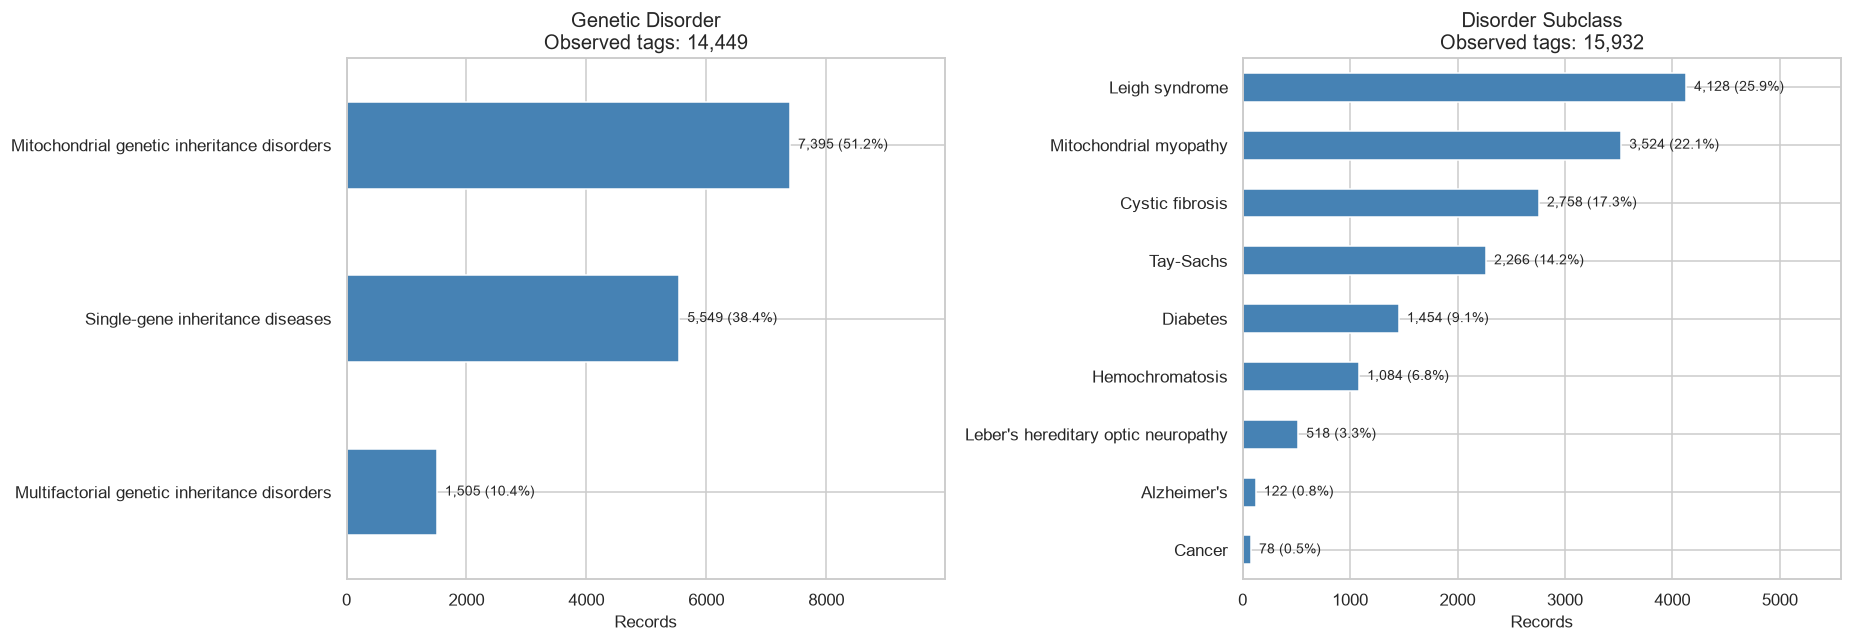

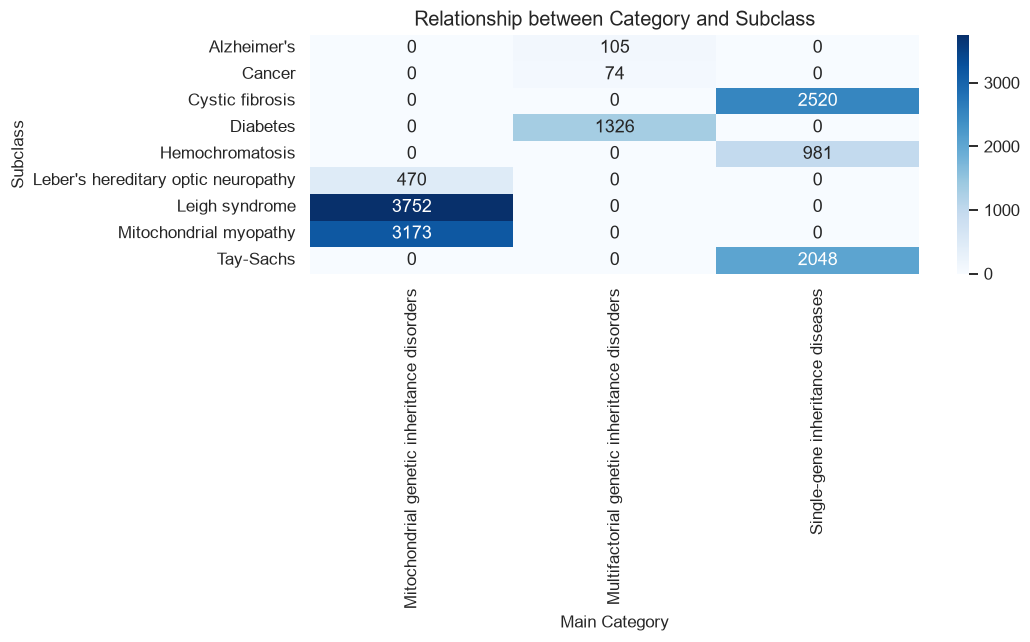

Main categories observed by subclass:


,n_categories
Disorder Subclass,
Alzheimer's,1
Cancer,1
Cystic fibrosis,1
Diabetes,1
Hemochromatosis,1
Leber's hereditary optic neuropathy,1
Leigh syndrome,1
Mitochondrial myopathy,1
Tay-Sachs,1


In [13]:
# =============================================================================
# EDA 3: CLASS BALANCE AND TARGET HIERARCHY
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

for ax, target in zip(axes, TARGET_COLUMNS):
    counts = eda_train[target].value_counts()
    percentages = counts.div(counts.sum()).mul(100)

    display(pd.DataFrame({
        "n": counts,
        "percentage": percentages.round(2),
    }))

    ordered = counts.sort_values()
    ordered.plot.barh(ax=ax, color="steelblue")

    ax.set_title(f"{target}\nObserved tags: {counts.sum():,}")
    ax.set_xlabel("Records")
    ax.set_ylabel("")

    for position, (label, count) in enumerate(ordered.items()):
        ax.text(
            count, position,
            f"  {count:,} ({percentages[label]:.1f}%)",
            va="center", fontsize=9,
        )

    ax.set_xlim(0, counts.max() * 1.35)

plt.tight_layout()
plt.show()

hierarchy = pd.crosstab(
    eda_train["Disorder Subclass"],
    eda_train["Genetic Disorder"],
)

plt.figure(figsize=(10, 6))
sns.heatmap(hierarchy, annot=True, fmt="d", cmap="Blues")
plt.title("Relationship between Category and Subclass")
plt.xlabel("Main Category")
plt.ylabel("Subclass")
plt.tight_layout()
plt.show()

print("Main categories observed by subclass:")
display(hierarchy.gt(0).sum(axis=1).to_frame("n_categories"))

,Training,Test,percentage_point_difference
Heart Rate (rates/min,8.96,52.55,43.59
Respiratory Rate (breaths/min),9.25,52.73,43.49
Institute Name,21.91,52.87,30.96
Maternal gene,12.17,39.33,27.16
Test 1,9.19,22.40,13.21
Folic acid details (peri-conceptional),9.05,22.10,13.05
No. of previous abortion,9.12,22.14,13.02
History of anomalies in previous pregnancies,9.17,22.16,12.99
Follow-up,9.10,22.08,12.98
Test 3,9.23,22.18,12.94


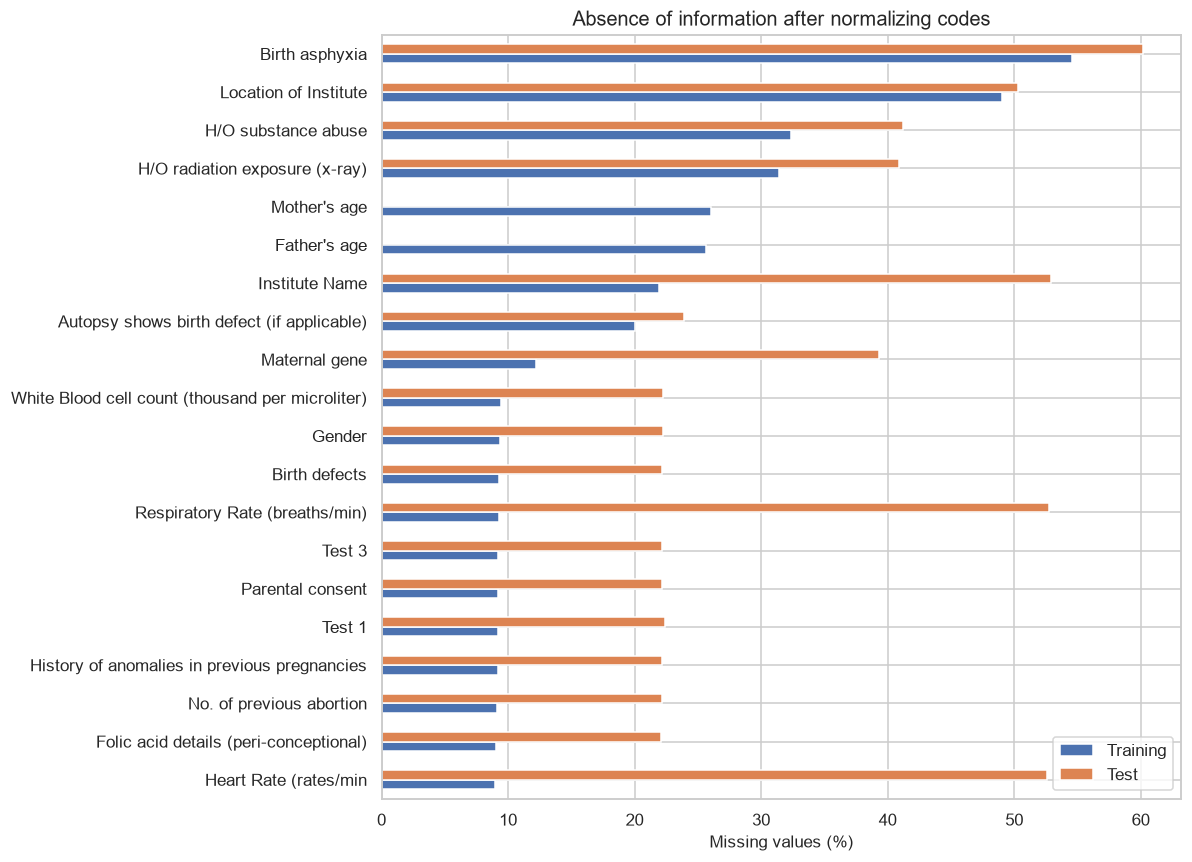

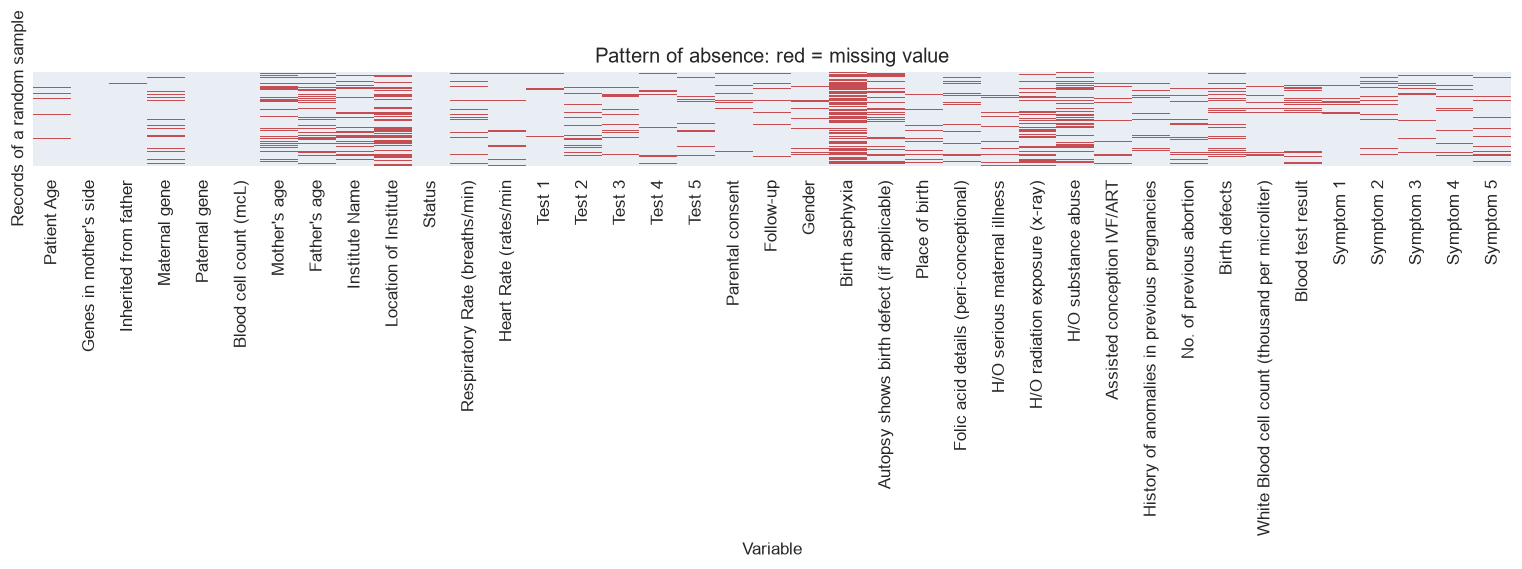

In [15]:
# =============================================================================
# EDA 4: MISSING DATA AND TRAIN–TEST DIFFERENCES
# =============================================================================

excluded_from_missing_plot = [
    "Patient Id", "Patient First Name",
    "Family Name", "Father's name",
]

feature_columns = [
    column for column in eda_test.columns
    if column not in excluded_from_missing_plot
]

missing_comparison = pd.DataFrame({
    "Training": (
        eda_train[feature_columns].isna().mean() * 100
    ),
    "Test": eda_test[feature_columns].isna().mean() * 100,
})

missing_comparison["percentage_point_difference"] = (
    missing_comparison["Test"]
    - missing_comparison["Training"]
)

display(
    missing_comparison
    .sort_values("percentage_point_difference", ascending=False)
    .round(2)
)

top_missing = (
    missing_comparison[["Training", "Test"]]
    .max(axis=1)
    .sort_values(ascending=False)
    .head(20)
    .index
)

missing_comparison.loc[
    top_missing, ["Training", "Test"]
].sort_values("Training").plot.barh(figsize=(11, 8))

plt.xlabel("Missing values (%)")
plt.title("Absence of information after normalizing codes")
plt.tight_layout()
plt.show()

missing_sample = eda_train[feature_columns].sample(
    n=min(300, len(eda_train)),
    random_state=EDA_SEED,
)

plt.figure(figsize=(14, 5))
sns.heatmap(
    missing_sample.isna(),
    cmap=["#e8eef3", "#c44e52"],
    cbar=False,
    yticklabels=False,
)
plt.title("Pattern of absence: red = missing value")
plt.xlabel("Variable")
plt.ylabel("Records of a random sample")
plt.tight_layout()
plt.show()

In [16]:
# =============================================================================
# EDA 5: SENSITIVITY TO COMPLETE-CASE DELETION
# =============================================================================

# Excluir identificadores, nombres e instituto para esta comparación.
analysis_columns = [
    column for column in eda_train.columns
    if column not in [
        "Patient Id", "Patient First Name",
        "Family Name", "Father's name",
        "Institute Name", "Location of Institute",
    ]
]

complete_cases = eda_train.dropna(subset=analysis_columns)

retention = pd.DataFrame({
    "estrategia": [
        "Etiqueta objetivo disponible",
        "Además, todos los campos analizados completos",
    ],
    "registros": [len(eda_train), len(complete_cases)],
    "clases_objetivo": [
        eda_train[EDA_TARGET].nunique(),
        complete_cases[EDA_TARGET].nunique(),
    ],
})

retention["retenido_%"] = (
    retention["registros"] / len(eda_train) * 100
)

display(retention.round(2))

status_comparison = pd.DataFrame({
    "Antes": eda_train["Status"].value_counts(normalize=True),
    "Casos completos": complete_cases["Status"].value_counts(
        normalize=True
    ),
}).mul(100)

display(status_comparison.round(2))

print(
    "Esta comparación conserva 'Not applicable' como categoría; "
    "no reproduce su conversión a faltante."
)

,estrategia,registros,clases_objetivo,retenido_%
0,Etiqueta objetivo disponible,15932,9,100.00
1,"Además, todos los campos analizados completos",1278,9,8.02


,Antes,Casos completos
Status,,
Alive,50.45,60.41
Deceased,49.55,39.59


Esta comparación conserva 'Not applicable' como categoría; no reproduce su conversión a faltante.


,count,mean,std,min,1%,25%,50%,75%,99%,max
Patient Age,14938.0,6.952,4.319,0.000,0.000,3.000,7.000,11.000,14.000,14.000
Mother's age,11780.0,34.582,9.824,18.000,18.000,26.000,35.000,43.000,51.000,51.000
Father's age,11851.0,41.971,13.105,20.000,20.000,30.000,42.000,53.000,64.000,64.000
Blood cell count (mcL),15932.0,4.899,0.199,4.093,4.443,4.763,4.899,5.033,5.365,5.592
White Blood cell count (thousand per microliter),14423.0,7.488,2.656,3.000,3.000,5.426,7.485,9.531,12.000,12.000
No. of previous abortion,14479.0,2.005,1.407,0.000,0.000,1.000,2.000,3.000,4.000,4.000


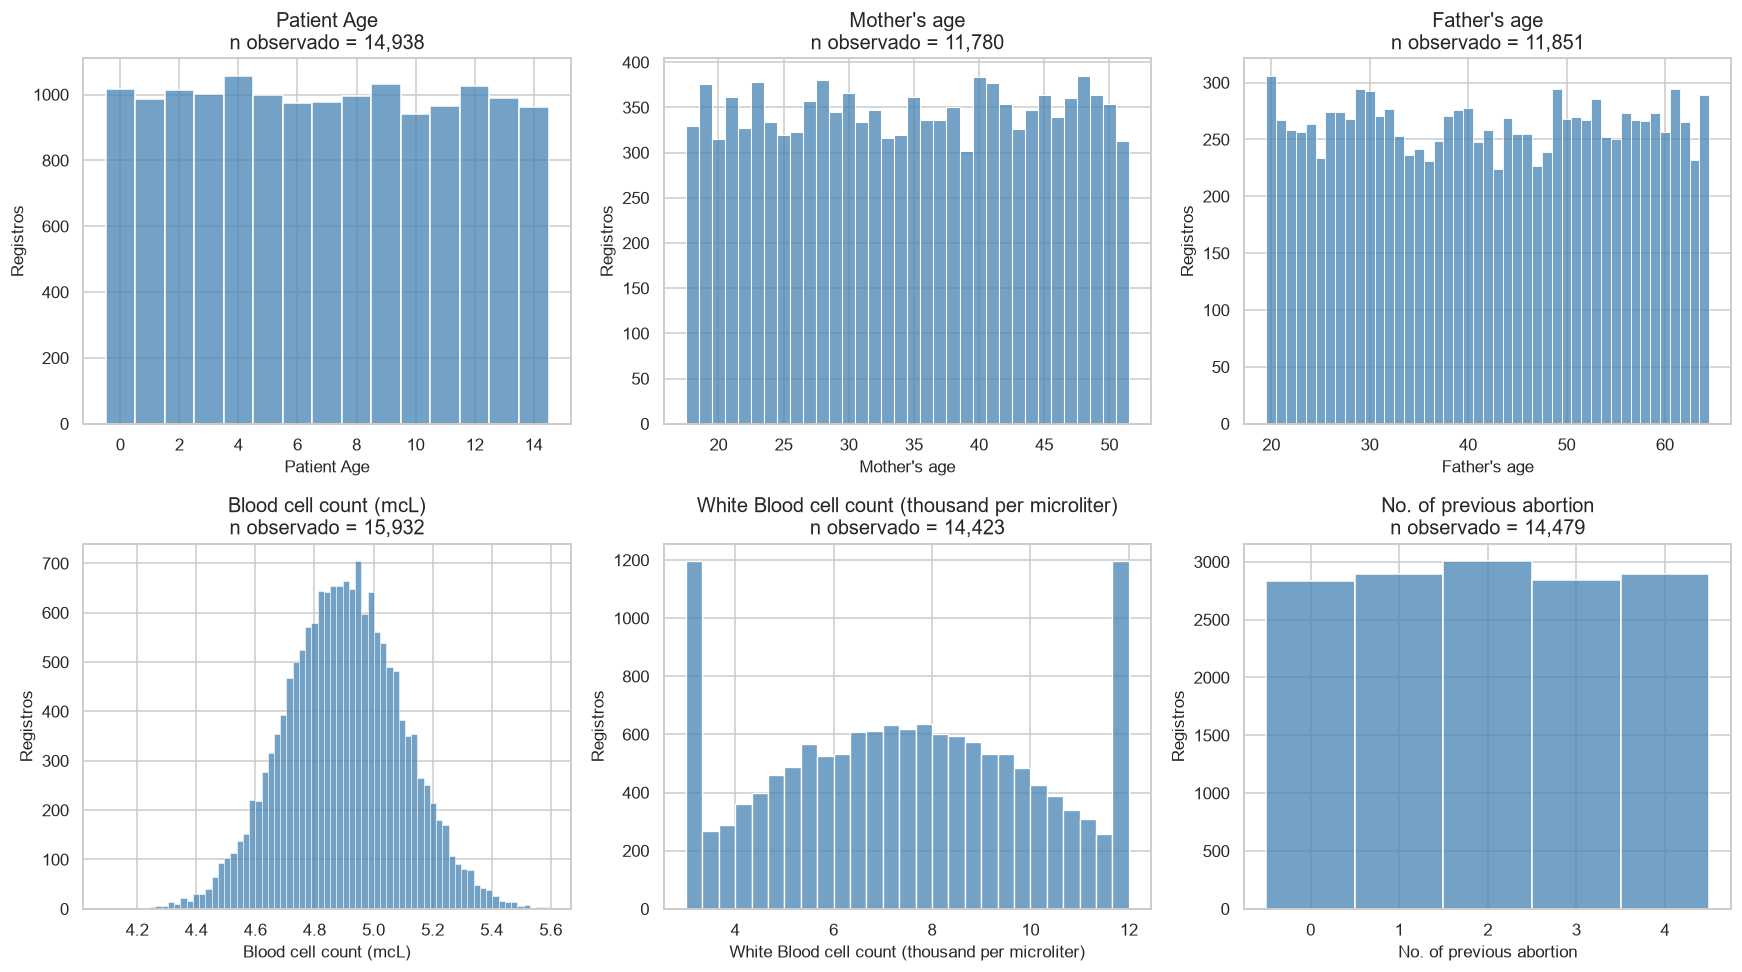

,variable,limite_inferior_IQR,limite_superior_IQR,fuera_limites_n,n_observado
0,Patient Age,-9.000,23.000,0,14938
1,Mother's age,0.500,68.500,0,11780
2,Father's age,-4.500,87.500,0,11851
3,Blood cell count (mcL),4.359,5.437,112,15932
4,White Blood cell count (thousand per microliter),-0.732,15.688,0,14423
5,No. of previous abortion,-2.000,6.000,0,14479


In [17]:
# =============================================================================
# EDA 6: NUMERIC DISTRIBUTIONS AND EXTREME VALUES
# =============================================================================

display(
    eda_train[NUMERIC_EDA_COLUMNS]
    .describe(percentiles=[0.01, 0.25, 0.50, 0.75, 0.99])
    .T
    .round(3)
)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, column in zip(axes.flat, NUMERIC_EDA_COLUMNS):
    values = eda_train[column].dropna()
    discrete = column in [
        "Patient Age", "Mother's age", "Father's age",
        "No. of previous abortion",
    ]

    sns.histplot(
        x=values,
        discrete=discrete,
        kde=False,
        ax=ax,
        color="steelblue",
    )
    ax.set_title(f"{column}\nn observado = {len(values):,}")
    ax.set_ylabel("Registros")

plt.tight_layout()
plt.show()

extreme_summary = []

for column in NUMERIC_EDA_COLUMNS:
    values = eda_train[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

    extreme_summary.append({
        "variable": column,
        "limite_inferior_IQR": lower,
        "limite_superior_IQR": upper,
        "fuera_limites_n": ((values < lower) | (values > upper)).sum(),
        "n_observado": len(values),
    })

display(pd.DataFrame(extreme_summary).round(3))


Variable: Patient Age


,n,mediana,q25,q75
Disorder Subclass,,,,
Leigh syndrome,3868,7.0,3.00,11.0
Mitochondrial myopathy,3316,7.0,3.00,11.0
Cystic fibrosis,2589,7.0,3.00,11.0
Tay-Sachs,2125,7.0,3.00,11.0
Diabetes,1349,7.0,3.00,11.0
Hemochromatosis,1016,7.0,3.00,11.0
Leber's hereditary optic neuropathy,484,7.0,3.00,10.0
Alzheimer's,118,6.0,3.25,10.0
Cancer,73,8.0,4.00,12.0


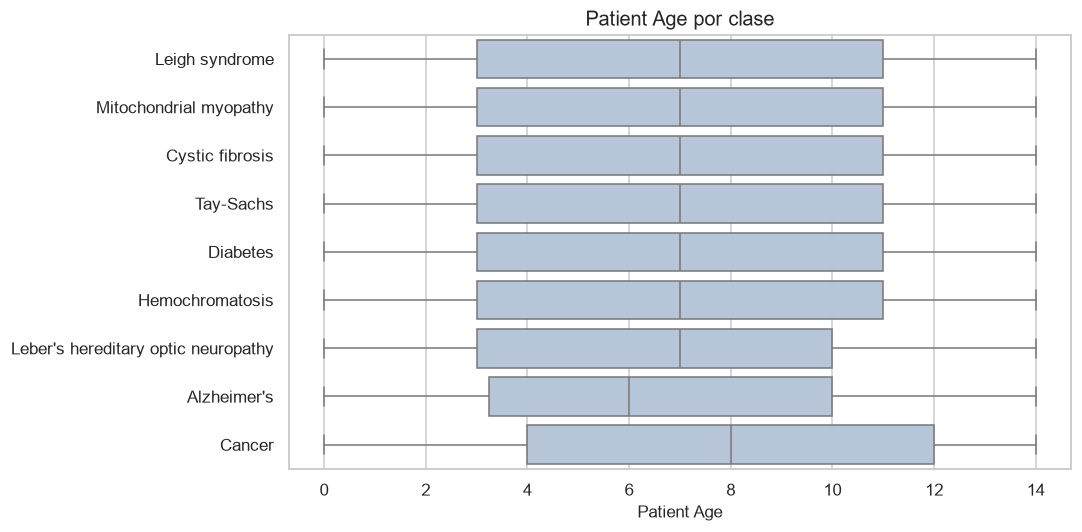


Variable: Mother's age


,n,mediana,q25,q75
Disorder Subclass,,,,
Leigh syndrome,3020,35.0,26.0,43.00
Mitochondrial myopathy,2595,35.0,26.0,43.00
Cystic fibrosis,2066,35.0,26.0,43.00
Tay-Sachs,1690,34.0,26.0,43.00
Diabetes,1087,35.0,26.0,43.00
Hemochromatosis,799,35.0,27.0,43.00
Leber's hereditary optic neuropathy,378,36.0,28.0,44.75
Alzheimer's,85,35.0,27.0,43.00
Cancer,60,34.5,25.0,42.00


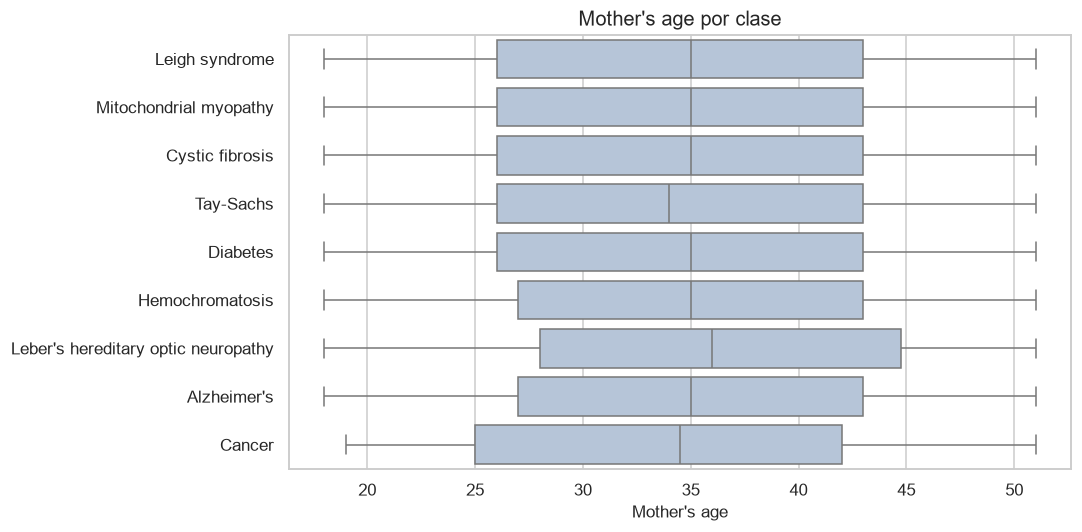


Variable: Father's age


,n,mediana,q25,q75
Disorder Subclass,,,,
Leigh syndrome,3026,41.0,30.00,53.00
Mitochondrial myopathy,2639,42.0,30.00,53.00
Cystic fibrosis,2052,42.0,31.00,53.00
Tay-Sachs,1689,42.0,31.00,53.00
Diabetes,1090,42.0,31.00,54.00
Hemochromatosis,820,43.0,31.00,54.00
Leber's hereditary optic neuropathy,390,41.0,31.00,55.00
Alzheimer's,89,44.0,32.00,56.00
Cancer,56,37.5,26.75,53.75


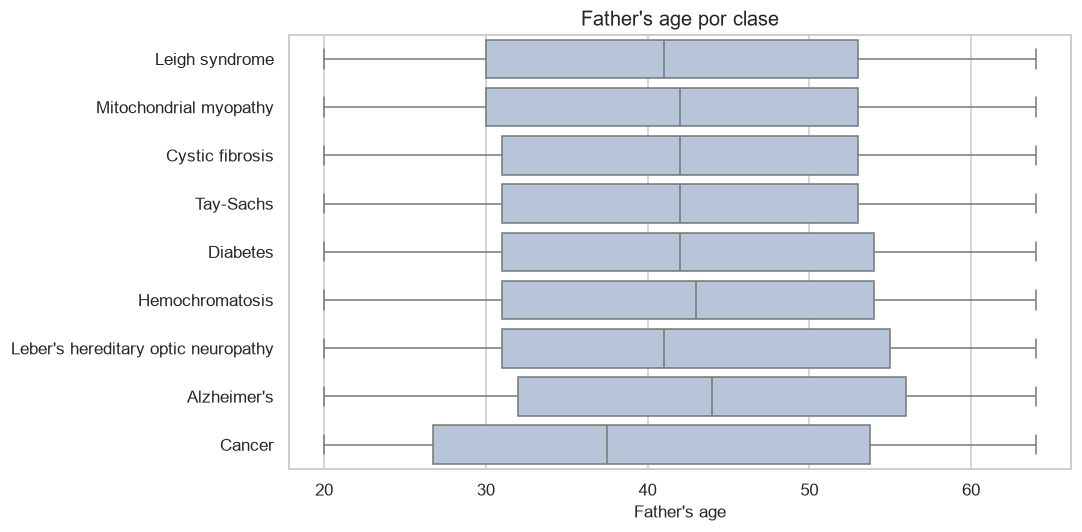


Variable: Blood cell count (mcL)


,n,mediana,q25,q75
Disorder Subclass,,,,
Leigh syndrome,4128,4.905,4.767,5.041
Mitochondrial myopathy,3524,4.897,4.759,5.026
Cystic fibrosis,2758,4.901,4.768,5.030
Tay-Sachs,2266,4.896,4.765,5.035
Diabetes,1454,4.891,4.764,5.038
Hemochromatosis,1084,4.893,4.752,5.023
Leber's hereditary optic neuropathy,518,4.899,4.772,5.036
Alzheimer's,122,4.920,4.732,5.036
Cancer,78,4.875,4.725,4.955


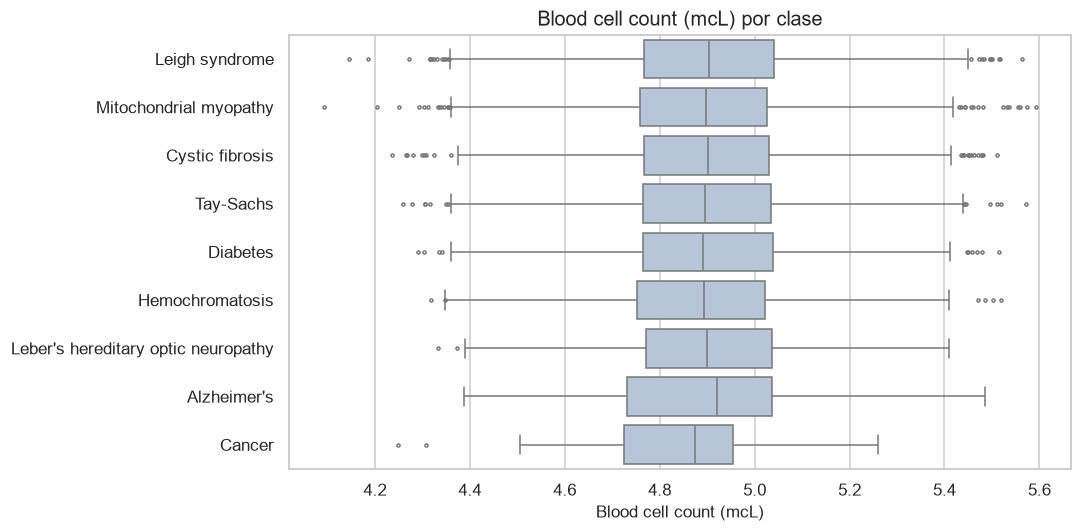


Variable: White Blood cell count (thousand per microliter)


,n,mediana,q25,q75
Disorder Subclass,,,,
Leigh syndrome,3718,7.460,5.420,9.467
Mitochondrial myopathy,3206,7.508,5.431,9.555
Cystic fibrosis,2482,7.485,5.525,9.537
Tay-Sachs,2068,7.496,5.398,9.429
Diabetes,1320,7.417,5.261,9.685
Hemochromatosis,971,7.490,5.329,9.504
Leber's hereditary optic neuropathy,476,7.684,5.585,9.747
Alzheimer's,109,7.624,4.956,10.072
Cancer,73,7.564,6.133,10.257


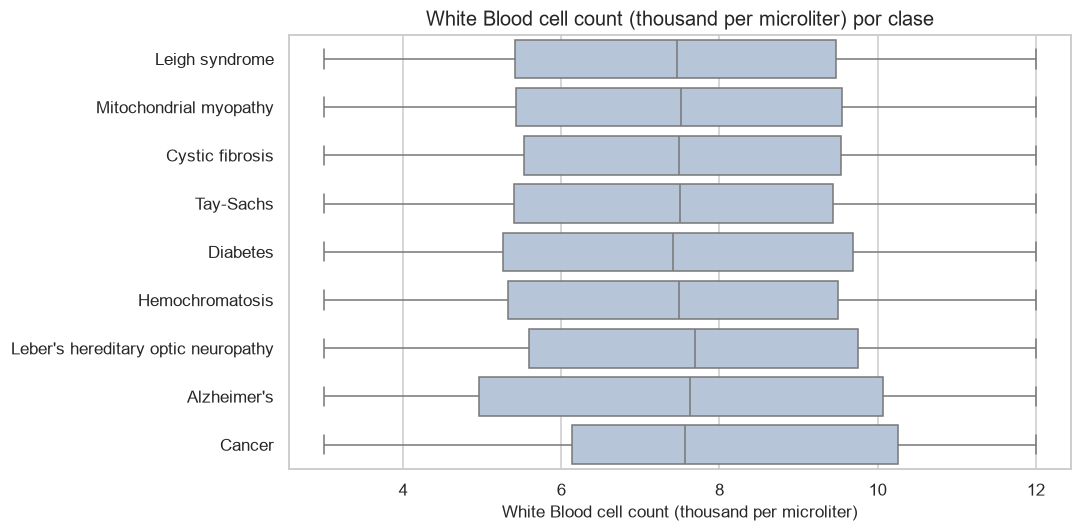


Variable: No. of previous abortion


,n,mediana,q25,q75
Disorder Subclass,,,,
Leigh syndrome,3746,2.0,1.0,3.0
Mitochondrial myopathy,3207,2.0,1.0,3.0
Cystic fibrosis,2524,2.0,1.0,3.0
Tay-Sachs,2058,2.0,1.0,3.0
Diabetes,1325,2.0,1.0,3.0
Hemochromatosis,963,2.0,1.0,3.0
Leber's hereditary optic neuropathy,472,2.0,1.0,3.0
Alzheimer's,115,2.0,1.0,3.0
Cancer,69,2.0,1.0,3.0


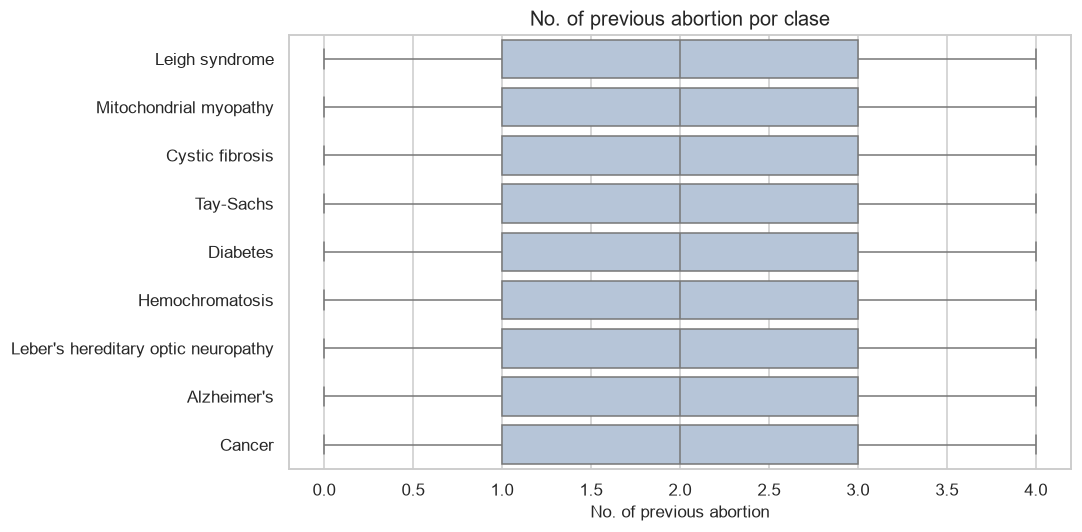

In [18]:
# =============================================================================
# EDA 7: NUMERIC VARIABLES BY TARGET CLASS
# =============================================================================

class_order = eda_train[EDA_TARGET].value_counts().index.tolist()

for column in NUMERIC_EDA_COLUMNS:
    summary = (
        eda_train.groupby(EDA_TARGET)[column]
        .agg(
            n="count",
            mediana="median",
            q25=lambda values: values.quantile(0.25),
            q75=lambda values: values.quantile(0.75),
        )
        .reindex(class_order)
    )

    print(f"\nVariable: {column}")
    display(summary.round(3))

    plt.figure(figsize=(10, 5))
    sns.boxplot(
        data=eda_train,
        x=column,
        y=EDA_TARGET,
        order=class_order,
        color="lightsteelblue",
        showfliers=True,
        fliersize=2,
    )
    plt.title(f"{column} por clase")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

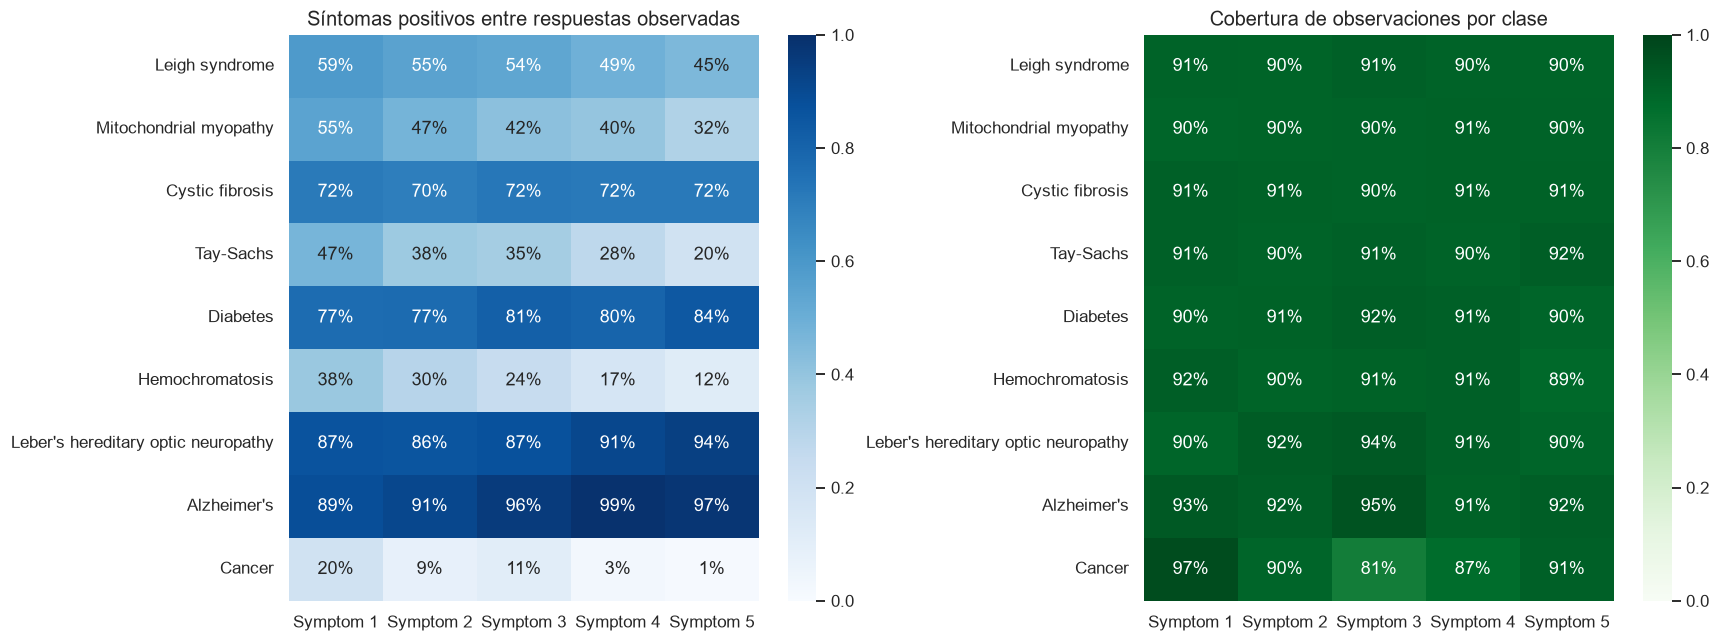

Número de observaciones por síntoma y clase:


,Symptom 1,Symptom 2,Symptom 3,Symptom 4,Symptom 5
Disorder Subclass,,,,,
Leigh syndrome,3737,3718,3764,3730,3720
Mitochondrial myopathy,3166,3170,3187,3205,3188
Cystic fibrosis,2516,2506,2493,2507,2508
Tay-Sachs,2063,2045,2067,2050,2086
Diabetes,1315,1321,1339,1325,1304
Hemochromatosis,998,974,985,989,960
Leber's hereditary optic neuropathy,464,479,485,472,464
Alzheimer's,114,112,116,111,112
Cancer,76,70,63,68,71


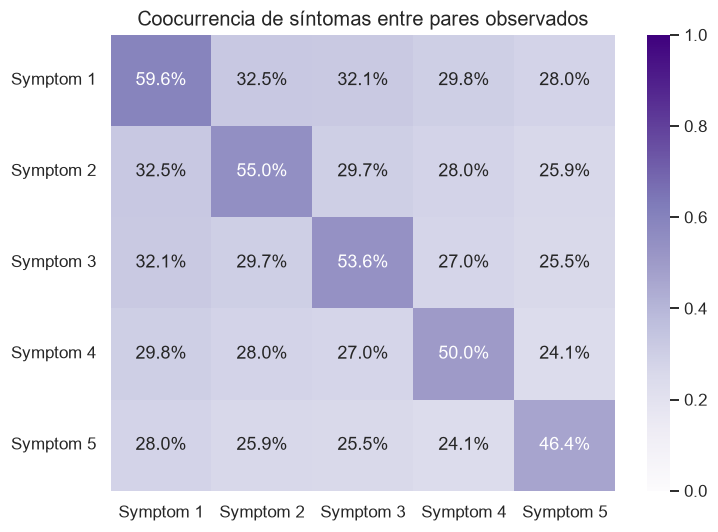

Número de registros que respaldan cada par:


,Symptom 1,Symptom 2,Symptom 3,Symptom 4,Symptom 5
Symptom 1,14449,13148,13205,13169,13130
Symptom 2,13148,14395,13161,13117,13107
Symptom 3,13205,13161,14499,13214,13163
Symptom 4,13169,13117,13214,14457,13154
Symptom 5,13130,13107,13163,13154,14413


In [19]:
# =============================================================================
# EDA 9: SYMPTOMS — PREVALENCE, COVERAGE AND COOCCURRENCE
# =============================================================================

grouped_symptoms = eda_train.groupby(EDA_TARGET)[SYMPTOM_COLUMNS]

symptom_prevalence = grouped_symptoms.mean().reindex(class_order)
symptom_observed = grouped_symptoms.count().reindex(class_order)

class_sizes = (
    eda_train.groupby(EDA_TARGET).size().reindex(class_order)
)

symptom_coverage = symptom_observed.div(class_sizes, axis=0)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(
    symptom_prevalence,
    annot=True, fmt=".0%",
    vmin=0, vmax=1,
    cmap="Blues",
    ax=axes[0],
)
axes[0].set_title("Síntomas positivos entre respuestas observadas")

sns.heatmap(
    symptom_coverage,
    annot=True, fmt=".0%",
    vmin=0, vmax=1,
    cmap="Greens",
    ax=axes[1],
)
axes[1].set_title("Cobertura de observaciones por clase")

for ax in axes:
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

print("Número de observaciones por síntoma y clase:")
display(symptom_observed)

# Proporción con ambos síntomas positivos,
# condicionada a que ambos estén observados.
cooccurrence = pd.DataFrame(
    np.nan, index=SYMPTOM_COLUMNS, columns=SYMPTOM_COLUMNS
)
pair_support = cooccurrence.copy()

for first in SYMPTOM_COLUMNS:
    for second in SYMPTOM_COLUMNS:
        observed = (
            eda_train[first].notna()
            & eda_train[second].notna()
        )
        pair_support.loc[first, second] = observed.sum()

        if observed.any():
            cooccurrence.loc[first, second] = (
                eda_train.loc[observed, first].eq(1)
                & eda_train.loc[observed, second].eq(1)
            ).mean()

plt.figure(figsize=(7, 5))
sns.heatmap(
    cooccurrence,
    annot=True, fmt=".1%",
    vmin=0, vmax=1,
    cmap="Purples",
)
plt.title("Coocurrencia de síntomas entre pares observados")
plt.tight_layout()
plt.show()

print("Número de registros que respaldan cada par:")
display(pair_support.astype(int))

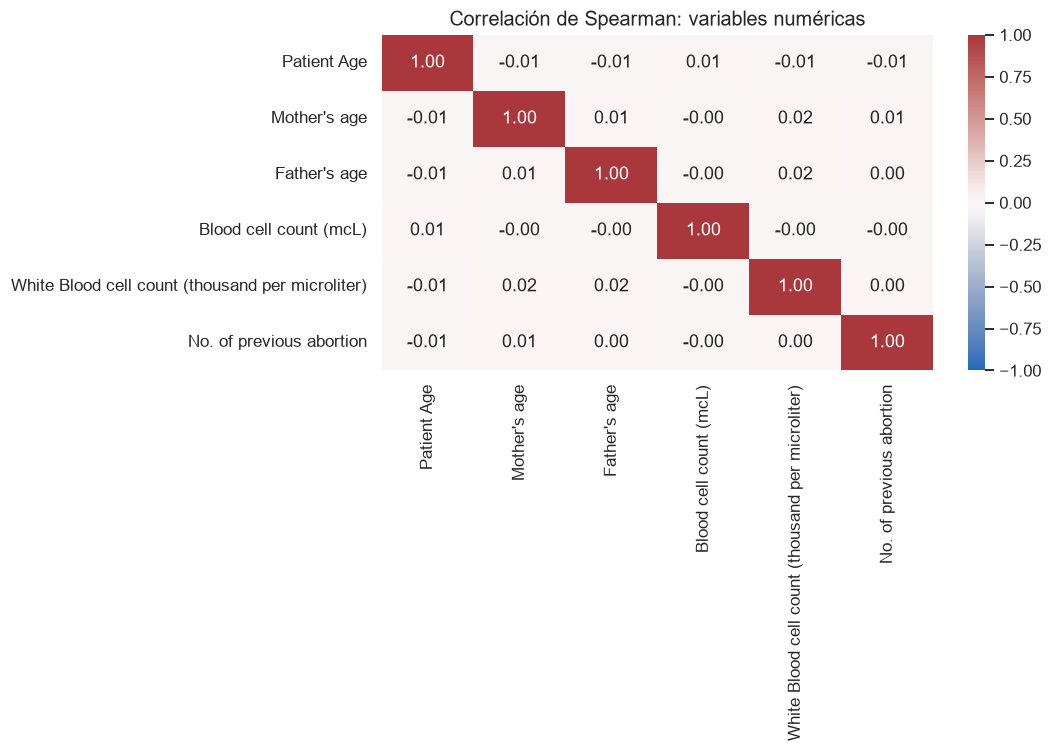

NameError: name 'CATEGORICAL_EDA_COLUMNS' is not defined

In [20]:
# =============================================================================
# EDA 10: ASSOCIATIONS AND REDUNDANCY
# =============================================================================

numeric_corr = eda_train[NUMERIC_EDA_COLUMNS].corr(
    method="spearman",
    min_periods=30,
)

plt.figure(figsize=(10, 7))
sns.heatmap(
    numeric_corr,
    annot=True, fmt=".2f",
    vmin=-1, vmax=1, center=0,
    cmap="vlag",
)
plt.title("Correlación de Spearman: variables numéricas")
plt.tight_layout()
plt.show()


def corrected_cramers_v(first, second):
    """V de Cramér con corrección de sesgo; usa pares observados."""
    paired = pd.DataFrame({"a": first, "b": second}).dropna()
    table = pd.crosstab(paired["a"], paired["b"])
    n = table.to_numpy().sum()

    if n <= 1 or min(table.shape) < 2:
        return np.nan, int(n)

    chi2 = chi2_contingency(table, correction=False)[0]
    rows, columns = table.shape

    phi2 = chi2 / n
    phi2_corrected = max(
        0, phi2 - ((columns - 1) * (rows - 1)) / (n - 1)
    )
    rows_corrected = rows - ((rows - 1)**2) / (n - 1)
    columns_corrected = columns - ((columns - 1)**2) / (n - 1)

    denominator = min(
        rows_corrected - 1,
        columns_corrected - 1,
    )

    if denominator <= 0:
        return np.nan, int(n)

    return np.sqrt(phi2_corrected / denominator), int(n)


association_rows = []

for column in CATEGORICAL_EDA_COLUMNS:
    association, n = corrected_cramers_v(
        eda_train[column],
        eda_train[EDA_TARGET],
    )
    association_rows.append({
        "variable": column,
        "V_Cramer": association,
        "pares_observados": n,
    })

categorical_associations = (
    pd.DataFrame(association_rows)
    .sort_values("V_Cramer", ascending=False)
)

display(categorical_associations.round(3))

sns.barplot(
    data=categorical_associations,
    x="V_Cramer",
    y="variable",
    color="steelblue",
)
plt.xlim(0, 1)
plt.title("Asociación categórica con el objetivo")
plt.ylabel("")
plt.tight_layout()
plt.show()

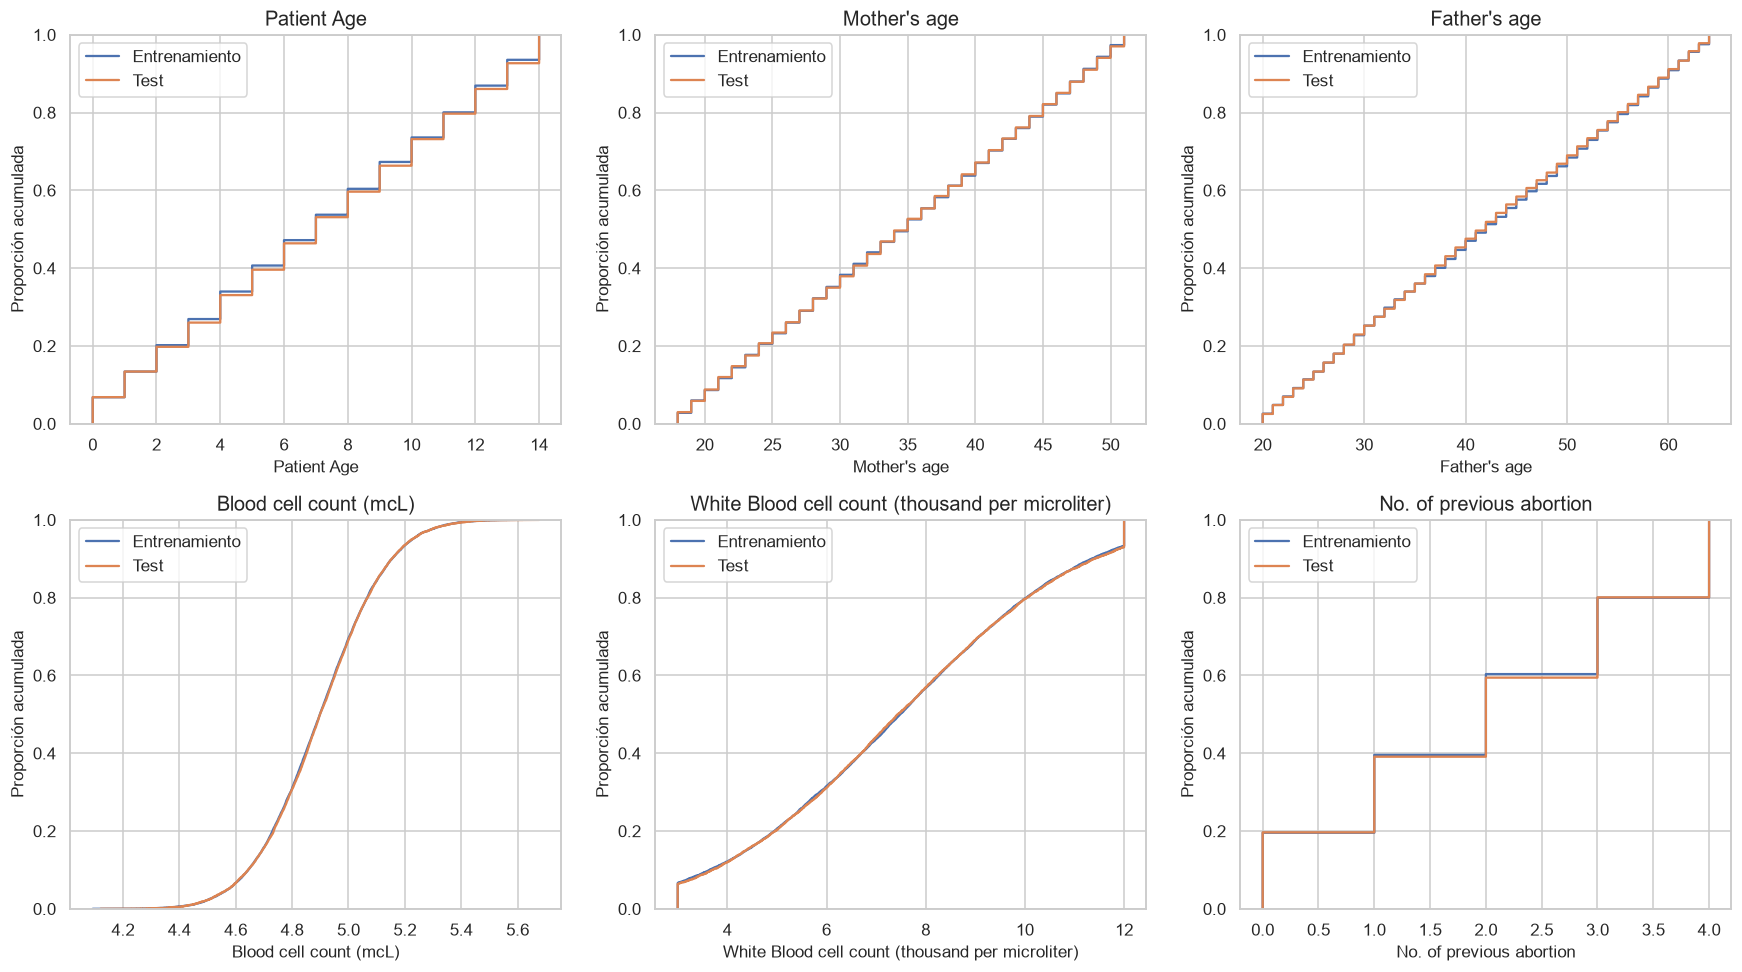

,variable,n_train,n_test,estadistico_KS
0,Patient Age,14938,9465,0.011
3,Blood cell count (mcL),15932,9465,0.010
2,Father's age,11851,9465,0.010
5,No. of previous abortion,14479,7369,0.009
4,White Blood cell count (thousand per microliter),14423,7363,0.008
1,Mother's age,11780,9465,0.005


NameError: name 'CATEGORICAL_EDA_COLUMNS' is not defined

In [21]:
# =============================================================================
# EDA 11: TRAIN–TEST DISTRIBUTION COMPARISON
# =============================================================================

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
shift_rows = []

for ax, column in zip(axes.flat, NUMERIC_EDA_COLUMNS):
    train_values = eda_train[column].dropna()
    test_values = eda_test[column].dropna()

    sns.ecdfplot(x=train_values, ax=ax, label="Entrenamiento")
    sns.ecdfplot(x=test_values, ax=ax, label="Test")

    ax.set_title(column)
    ax.set_ylabel("Proporción acumulada")
    ax.legend()

    if len(train_values) and len(test_values):
        shift_rows.append({
            "variable": column,
            "n_train": len(train_values),
            "n_test": len(test_values),
            "estadistico_KS": ks_2samp(
                train_values, test_values
            ).statistic,
        })

plt.tight_layout()
plt.show()

display(
    pd.DataFrame(shift_rows)
    .sort_values("estadistico_KS", ascending=False)
    .round(3)
)

# Categorías de test no observadas en entrenamiento.
new_categories = []

for column in CATEGORICAL_EDA_COLUMNS:
    known = set(eda_train[column].dropna().unique())
    incoming = set(eda_test[column].dropna().unique())
    unseen = incoming - known

    if unseen:
        new_categories.append({
            "variable": column,
            "categorias_nuevas_test": sorted(unseen, key=str),
        })

display(pd.DataFrame(
    new_categories,
    columns=["variable", "categorias_nuevas_test"],
))

print(
    "El estadístico KS describe diferencias en las distribuciones "
    "observadas; no establece por sí solo su causa ni su impacto predictivo."
)

,registros
Institute Name,
Not applicable,6129
Unknown,3491
Franciscan Children's Hospital,277
Carney Hospital,269
New England Medical Center,263
Shriners Burns Institute,260
VA Hospital,259
Boston City Hospital,254
Faulkner Hospital,252


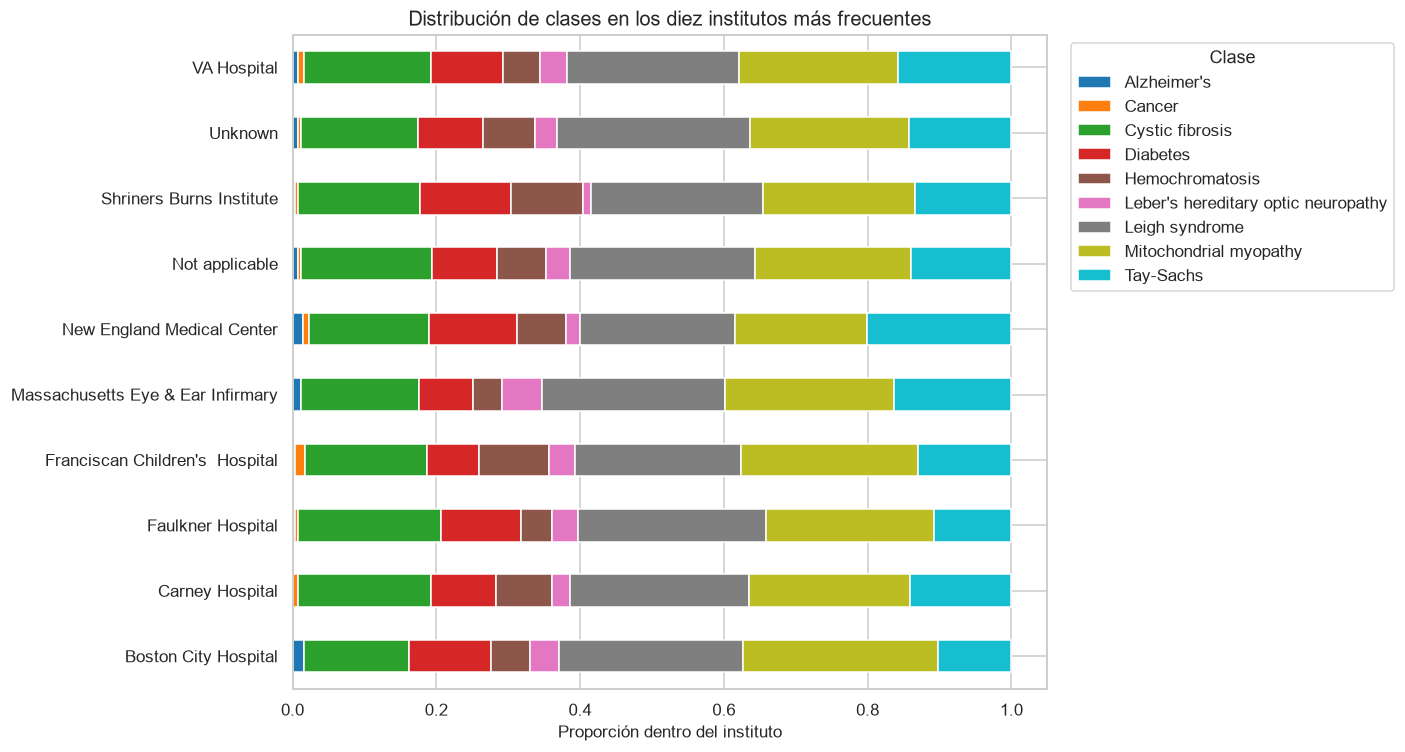

,variable,revision,decision_inicial
0,Patient Id y nombres,"Identificadores, no características clínicas",Excluir de las entradas
1,Status,Confirmar disponibilidad en el momento de pred...,Excluir para predicción previa al desenlace
2,Autopsy shows birth defect (if applicable),Información procedente de autopsia,Excluir para predicción previa al desenlace
3,Follow-up,Confirmar significado y momento de registro,Excluir hasta aclarar disponibilidad
4,Institute Name / Location of Institute,Posible dependencia del centro de origen,Conservar como metadatos para validación
5,Genetic Disorder / Disorder Subclass,Etiquetas de salida,Excluir ambas de las entradas


In [22]:
# =============================================================================
# EDA 12: INSTITUTE EFFECTS AND LEAKAGE AUDIT
# =============================================================================

institute = eda_train["Institute Name"].fillna("Unknown")

institute_counts = institute.value_counts()
display(institute_counts.to_frame("registros"))

top_institutes = institute_counts.head(10).index
selected = institute.isin(top_institutes)

institute_targets = pd.crosstab(
    institute.loc[selected],
    eda_train.loc[selected, EDA_TARGET],
    normalize="index",
)

institute_targets.plot.barh(
    stacked=True,
    figsize=(13, 7),
    colormap="tab10",
)
plt.xlabel("Proporción dentro del instituto")
plt.ylabel("")
plt.title("Distribución de clases en los diez institutos más frecuentes")
plt.legend(title="Clase", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

availability_audit = pd.DataFrame([
    {
        "variable": "Patient Id y nombres",
        "revision": "Identificadores, no características clínicas",
        "decision_inicial": "Excluir de las entradas",
    },
    {
        "variable": "Status",
        "revision": "Confirmar disponibilidad en el momento de predicción",
        "decision_inicial": "Excluir para predicción previa al desenlace",
    },
    {
        "variable": "Autopsy shows birth defect (if applicable)",
        "revision": "Información procedente de autopsia",
        "decision_inicial": "Excluir para predicción previa al desenlace",
    },
    {
        "variable": "Follow-up",
        "revision": "Confirmar significado y momento de registro",
        "decision_inicial": "Excluir hasta aclarar disponibilidad",
    },
    {
        "variable": "Institute Name / Location of Institute",
        "revision": "Posible dependencia del centro de origen",
        "decision_inicial": "Conservar como metadatos para validación",
    },
    {
        "variable": "Genetic Disorder / Disorder Subclass",
        "revision": "Etiquetas de salida",
        "decision_inicial": "Excluir ambas de las entradas",
    },
])

display(availability_audit)